# 03_sbi: simulation-based inference of the Jansen-Rit gain parameters

This notebook infers the Jansen-Rit gain parameters (`g_1`...`g_4`) from the empirical PCIst values, using simulation-based inference (SBI, specifically SNPE from the `sbi` package). It loads its data directly from what `01_general.ipynb` saved to `data/processed/`, it does not touch raw `.mat` files or recompute any empirical PCIst values.

Structure:
1. Setup and loading the preprocessed data
2. What SBI is doing here, and why
3. Prior, simulations, and noise
4. Gain matrix: the trick that lets a single channel model be compared to 16 channel data
5. Pipelines 0 to 2, as a progression from one shared gain matrix to a per-condition gain matrix
6. Comparing the posteriors across P0 to P2
7. Comparing the gain matrices across P0 to P2
8. Trying unweighted gain matrix
9. Appendix: Pipelines 3 and 4 (fully personalized, per-subject and per-subject-per-trial gain matrices), kept for reference but slow to train and not part of the main flow. And a bit outdated.

**A note on runtime**: pipelines 3 and 4 (in the appendix) retrain the whole SBI dataset with more gain matrices, and 4 additionally loops over subjects and trials, so those cells can run for a while, especially on my 4GB laptop GPU. They are skipped by default by living at the end of the notebook. Where a cell elsewhere is expensive it still says so, and the config variables to make a cheaper first pass are called out explicitly.

## Setup

Assumes this notebook lives in the project root, next to `src/` and `data/`, same as `01_general.ipynb`.

In [278]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import xarray as xr
from sklearn import preprocessing

import torch
import sbi
import sbi.inference

import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display
import pickle

from tqdm.auto import tqdm

sys.path.append(os.path.abspath('src'))
import data as dat
import jansen_rit as jrm
import pcist
import inference_utils as infr
import plotting

plotting.apply_house_style()

print('JAX backend:', jax.default_backend())
print('torch:', torch.__version__, '| sbi:', sbi.__version__)

DATA_ROOT = 'data'
PROCESSED_DIR = os.path.join(DATA_ROOT, 'processed')
PARENT_DIR = os.getcwd()

ANES_TYPES = ['keta', 'prop', 'sevo']
device = 'cpu'  # sbi/SNPE device. The PCIst + forward projection side (pcist.py, jax) is what actually
                # benefits from the GPU, that's controlled separately below (jax picks it up automatically).

JAX backend: gpu
torch: 2.5.1+cu124 | sbi: 0.25.0


### Loading what Notebook 1 produced

Everything here comes straight from `data/processed/`: the trial-averaged and trial-resolved ERPs, and the empirical PCIst values (both the single value per subject/condition, and the per-trial version). No raw `.mat` file gets touched in this notebook.

In [2]:
erp_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_all_erps.nc')) for anes in ANES_TYPES}
trial_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_single_trials.nc')) for anes in ANES_TYPES}

pcist_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_pcist.nc')) for anes in ANES_TYPES}
pci_trial_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_pci_trials.nc')) for anes in ANES_TYPES}

combined_erp = xr.concat(list(erp_datasets.values()), dim='condition')

# pooled across every anesthesia type, used later on (delay range sweep, prior range check,
# the dmax distribution slider) as the reference for where real PCIst values actually sit
emp_all = np.concatenate([pcist_datasets[a].values.ravel() for a in ANES_TYPES])

for anes in ANES_TYPES:
    print(f'{anes}: {erp_datasets[anes].sizes["subject"]} subjects, '
          f'trial-resolved n_trials={trial_datasets[anes].sizes["trial"]}')
print(f'empirical PCIst range (all anesthesia types pooled): {emp_all.min():.1f} to {emp_all.max():.1f}')

keta: 8 subjects, trial-resolved n_trials=5
prop: 9 subjects, trial-resolved n_trials=5
sevo: 10 subjects, trial-resolved n_trials=5
empirical PCIst range (all anesthesia types pooled): 28.8 to 112.8


The PCIst time convention used for these empirical values (and that any new,
simulated PCIst computation has to match) is the same one from Notebook 1:
sample index 100 is the stimulus onset, everything before is baseline,
everything after is the response window.

In [3]:
n_timepoints = erp_datasets['keta'].sizes['time']
baseline_len = 100  # raw crop starts exactly 100 ms before stimulus onset
time_vec = np.linspace(-baseline_len, n_timepoints - baseline_len - 1, n_timepoints)

pci_pars = dict(baseline_window=(time_vec.min(), 0), response_window=(0, time_vec.max()),
                 k=1.2, min_snr=1.1, max_var=99, embed=False, n_steps=100)

print('n_timepoints:', n_timepoints, '-> time_vec runs from', time_vec.min(), 'to', time_vec.max())
pci_pars

n_timepoints: 599 -> time_vec runs from -100.0 to 498.0


{'baseline_window': (np.float64(-100.0), 0),
 'response_window': (0, np.float64(498.0)),
 'k': 1.2,
 'min_snr': 1.1,
 'max_var': 99,
 'embed': False,
 'n_steps': 100}

## Why simulation-based inference

Notebook 2 (MCMC) fits the Jansen-Rit model directly to one subject's mean
ERP waveform: the likelihood of the observed time series given the
parameters is evaluated (implicitly, through NUTS) at every step, for one
subject and one channel at a time.

That does not scale well to this dataset. We have up to 10 subjects, 3
anesthesia types, and want conclusions about the whole group, not one
subject's one channel. Re-running NUTS per subject/condition/channel is slow.

SBI sidesteps both problems:

- Instead of the full waveform, we work with a single summary statistic per
  observation: PCIst. It is a good candidate here because it is the practical measure of
  "how complex/differentiated is the evoked response", which is what
  changes between wake and anesthesia.
- Instead of evaluating a likelihood, SNPE (Sequential Neural Posterior
  Estimation) learns the mapping from summary statistic to posterior
  directly: simulate many (parameters, PCIst) pairs from the prior, train a
  neural density estimator on those pairs, and it gives you
  $p(\theta \mid \text{PCIst})$ for any new PCIst value, instantly, no
  retraining needed per subject. That is what makes it practical to run this
  on every subject and condition in the dataset.

The catch is that the Jansen Rit simulations only result in single-channel signals, while we need 16-channel simulations to be able to compute the PCIst value of these simulations. That's what the gain matrix section below is for.

## Prior generation and simulations

We use one shared prior and one shared set of simulations for every pipeline below, so the pipelines are actually comparable to each other, they only differ in how the simulations get turned into training features.

In this notebook, we only infer the gain parameters (`jansen_rit.FREE_PARAM_NAMES`), keeping the rest at `jansen_rit.DEFAULT_PARAMS`.

In [4]:
# simulation time grid, lined up with the empirical time axis convention (stimulus at t=0,
# same pulse input as used in Notebook 1's Jansen-Rit background section)
# RK4, dt=1.0 ms, same integrator and step used everywhere in this project now (see
# 01_general.ipynb's "Errors and integrators" section), the grid is already at 1 ms
# per sample so ds_sim=1, no further downsampling needed
ts = jnp.arange(-100.0, 499.0, 1.0)
dt = 1.0
ds_sim = 1
nt = ts.shape[0]

input_params = (20.0, 6.0, 15.0)  # amplitude, width (ms), center (ms), same pulse as Notebook 1

prm_names = jrm.FREE_PARAM_NAMES
param_labels = {p: f'${p}$' for p in prm_names}
num_params = len(prm_names)
prm_names, num_params

(['g_1', 'g_2', 'g_3', 'g_4'], 4)

The prior mean/std per parameter is kept in a small dict below, keyed by parameter name rather than position, so extending `FREE_PARAM_NAMES` later just means adding an entry in the cell above, nothing else in this section needs restructuring.

The priors were chosen to be normal (independent Gaussian per parameter), centered on the DCM defaults with a 30 percent coefficient of variation. See Notebook 1's "Choosing a prior: normal vs. log-uniform" section for the full comparison and reasoning.

Keeping this in a dict keyed by parameter name, same as before, so extending FREE_PARAM_NAMES later is still just adding an entry here.

Here we also decide what number of simulations we want to run, which will be used for the rest of the notebook, by altering `num_sim` (1000 is used for light runs, 10 000 for heavy runs).

In [5]:
prior_cv = 0.3  # coefficient of variation, same for every g, see Notebook 1
prior_means = {p: jrm.DEFAULT_PARAMS_TEMPORAL[p] for p in prm_names}
prior_stds = {p: prior_cv * prior_means[p] for p in prm_names}

theta_means = [prior_means[p] for p in prm_names]
theta_stds = [prior_stds[p] for p in prm_names]

num_sim = 1000
prior_type = 'normal'
sim_name = f'JR_EC_{num_sim}'
sim_path, posterior_path = infr.init_sim_dirs(PARENT_DIR, sim_name)

prior = infr.make_prior(theta_means, theta_stds, prm_names, sim_path=sim_path, overwrite=True, dist_type=prior_type)
prior

Independent(Normal(loc: torch.Size([4]), scale: torch.Size([4])), 1)

### Noise

`jansen_rit.simulate_erp_temporal` can add three kinds of noise on top of the
clean trace: a constant bias, and a damped (low pass filtered) white noise,
controlled by `noise_params = (bias_amplitude, white_amplitude, noise_tau)`.
Notebook 1's "Different kinds of input, and noise" section demonstrates this. 

For now we will use the same noise parameters (no noise) as in notebook 1.

In [6]:
noise_params = (0.0, 0.0, 10)  # bias amplitude, white noise amplitude, noise_tau (see note above); no noise, see Notebook 1's decision

### Manual loop simulation

First, let's sample and simulate `n_demo=50` simulations from the prior.

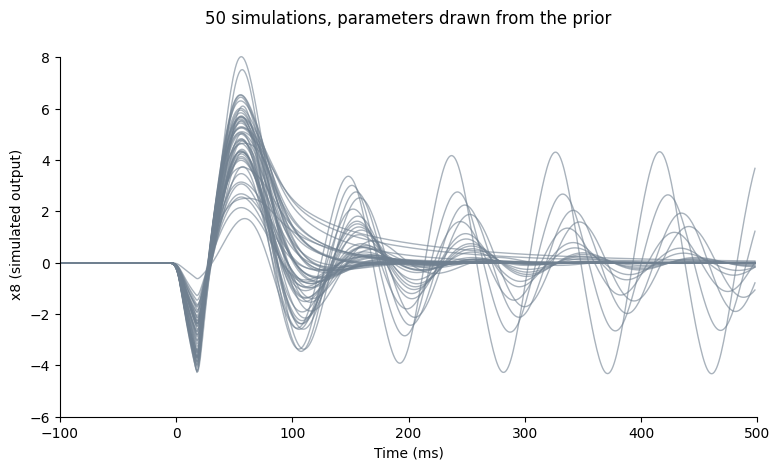

In [242]:
key = jax.random.PRNGKey(0)
n_demo = 50

demo_theta = infr.sample_from_prior(prior, n_demo, sim_path=sim_path, overwrite=True)

fig, ax = plt.subplots(figsize=(9, 5))
for i in range(n_demo):
    key, subkey = jax.random.split(key)
    free_params = dict(zip(prm_names, demo_theta[i, :].numpy()))
    trace = jrm.simulate_erp_temporal(ts, input_params, free_params=free_params, key=subkey, noise_params=noise_params)
    ax.plot(ts[::ds_sim], trace[::ds_sim], alpha=0.6, lw=1, color='slategray')

ax.set_xlabel('Time (ms)')
ax.set_ylabel('x8 (simulated output)')
ax.set_title(f'{n_demo} simulations, parameters drawn from the prior')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(ts.min()), 500), ylim=(-6, 9), yticks=np.arange(-6, 9, 2))
plt.show()

Now we can plot the sampled prior samples:

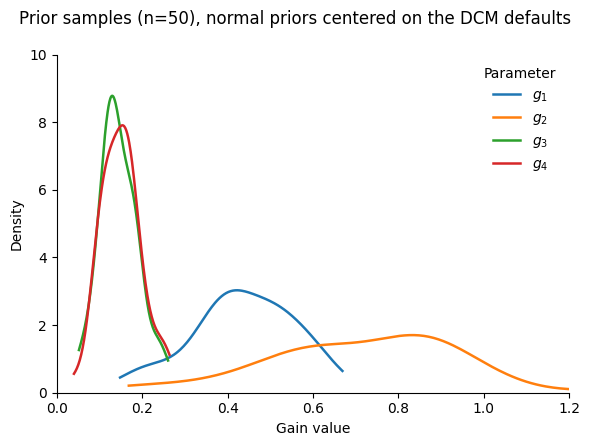

In [8]:
colors = sns.color_palette('tab10', num_params)

fig, ax = plt.subplots(figsize=(6, 4.5))
for i, prm in enumerate(prm_names):
    sns.kdeplot(demo_theta[:, i].numpy(), color=colors[i], ax=ax, cut=0, lw=1.8, label=param_labels[prm])

ax.set_xlabel('Gain value')
ax.set_ylabel('Density')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 1), xticks=np.arange(0, 1.21, 0.2),
                             ylim=(0, 10), yticks=np.arange(0, 10.01, 2))
ax.legend(frameon=False, title='Parameter')
fig.suptitle(f'Prior samples (n={n_demo}), normal priors centered on the DCM defaults')
fig.tight_layout()
plt.show()

### Big simulation for the actual training set

Now the real thing: `num_sim` draws from the prior, simulated and saved to `input/{sim_name}/`. This is the expensive cell in this section, be  carefull with making `num_sim` much higher. (Takes approximatly 3 min for 1000 simulations and 30 min for 10 000 simulations)

If `regenerate_simulations` is put on False then the simulations are loaded in from storage, if True then the simulations are performed again.

In [9]:
regenerate_simulations = False

if regenerate_simulations:
    theta = infr.sample_from_prior(prior, num_sim, sim_path=sim_path, overwrite=True)
    infr.simulate_from_theta(theta, sim_path, input_params, ts, nt, ds_sim=ds_sim,
                              noise_params=noise_params, free_param_names=prm_names,
                              num_batches=1, save_sims=True)
    sim_array, theta = infr.load_all_simulations(sim_path)
    sim_array = xr.DataArray(sim_array, dims=('simulation', 'time'))
    sim_array.to_netcdf(sim_path + '/simulations.nc')
else:
    sim_array, theta = infr.load_all_simulations(sim_path)
    sim_array = xr.DataArray(sim_array, dims=('simulation', 'time'))

print('sim_array:', sim_array.shape, '| theta:', theta.shape)

sim_array: (1000, 599) | theta: torch.Size([1000, 4])


Again we can plot these simulations.

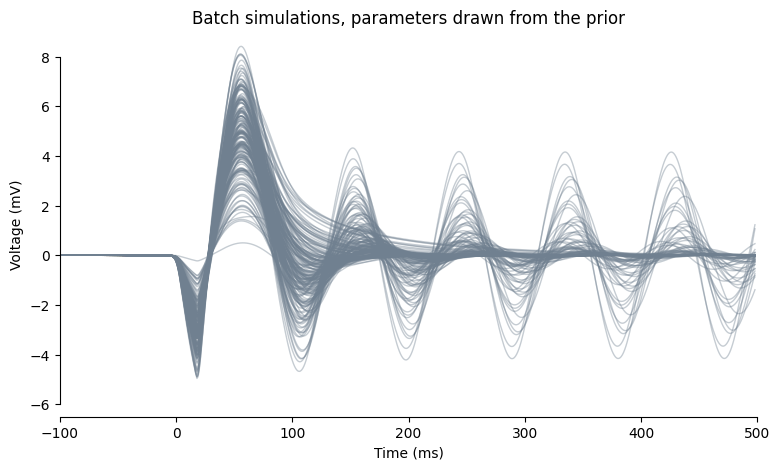

In [243]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ts[::ds_sim], sim_array[::5].T, lw=1, alpha=0.4, color='slategray')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (mV)')
ax.set_title('Batch simulations, parameters drawn from the prior')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(ts.min()), 500),  ylim=(-6.5, 9), yticks=np.arange(-6, 9, 2))
plt.show()

This gives the same result as in Notebook 1.

## Gain matrix: concept

PCIst needs multi-channel data (see Notebook 1), but the Jansen-Rit model as used here simulates a single cortical source, one
time series. Something has to bridge single-channel simulations to 16-channel sensor data before PCIst can be computed on them at all.

The approach here: use the empirical ERPs to build a gain matrix, which consists of the top 4 spatial principal components (via SVD) of the 16-channel empirical data. Those 4 components define 4 "modes". For a given single-channel simulation we build 4 slightly time-shifted copies (one per mode, `infr.compute_forward_solution_multimode_jax`), then combine them through the gain matrix to get a 16-channel simulated signal. The time shifts are what keep the 4 modes from being perfectly identical copies of each other.

- We simulate 1 channel (1 time series) using the Jansen-Rit model.
- We create 4 delayed copies of this (e.g. delays of 0, 110, 220, 330 ms).
- The undelayed copy corresponds to component 1, the first delayed copy to component 2, and so on up to component 4.
- If the underlying simulated value at time t is high, the contribution of that 16 channel component at that time is also high; if it is 0, the contribution is 0.
- We add up the contributions of the four (16 channel) components, to end up with a 16 channel simulation.


These 16 channel simulations are still all linked to the original parameter set from which we simulated the 1 channel Jansen-Rit simulation. This is what we want. Because every one of the 16 output channels is just a fixed linear combination of a handful of delayed copies of that single trace. Therefore it is still allowed to link the 16 channel simulation to the original g-parameters from which they were created. Making the rest of the notebook valid.

This whole gain matrix strategy is a modeling convenience that makes PCIst computable on the model output, not a claim that real propagation delays of that exact size exist between these components, which is worth keeping in mind.

One setting gets decided later in this notebook (see "Gain matrix
invariance" under Pipeline 1) but is needed already here: `weight_by_variance`.

This refers to the fact that normally the different components inside the gain matrix have unit-norm. But it turns out (see further) that in the case of unit-norm components that PCIst is exactly invariant to which gain matrix
gets used. This would make the whole point of building different gain
matrices per condition/subject/trial pointless later on. 


So this notebook uses `weight_by_variance=True` everywhere a gain matrix gets built, starting here. 


In the end of this Notebook we revisit the idea of unit-norm components.

In [11]:
weight_by_variance_gain = True

### How many components do we need?

Before trusting "4 components" as a reasonable choice, we check how much variance 4 components actually explain, both for a random single trial and for the average of all trial averages (see P0).

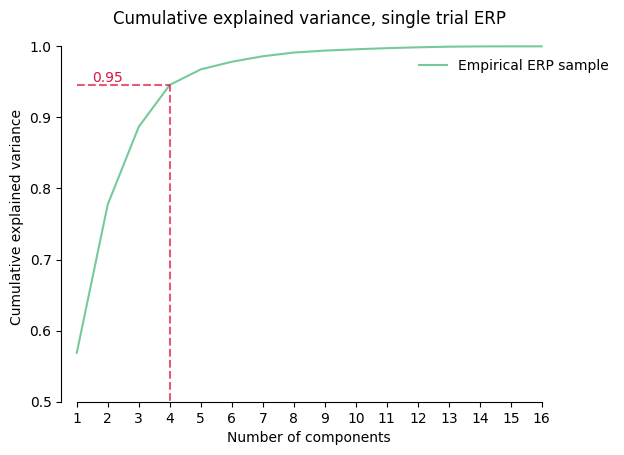

In [12]:
example_trial_erp = trial_datasets['keta'].sel(condition='wake', subject='j12').isel(trial=0).to_numpy()

fig, ax = plt.subplots()
plotting.plot_cumulative_explained_variance(fig, ax, example_trial_erp, n_comp_highlight=4,
                                             p_color='mediumseagreen', p_label='Empirical ERP sample', calpha=0.7, lw=1.5)
plotting.modify_axis_spines(ax, which=['x', 'y'], xticks=list(range(1, 17)), yticks=[0.5, 0.6, 0.7, 0.8, 0.9, 1])
ax.set_ylim(0.50, 1.02)
ax.set_title('Cumulative explained variance, single trial ERP')
plt.show()

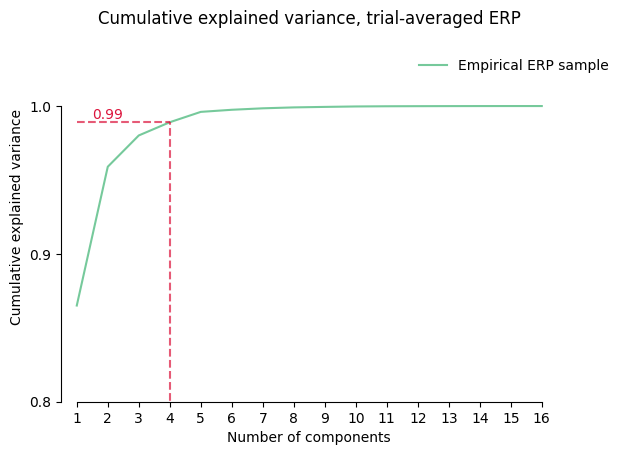

In [13]:
example_avg_erp = combined_erp.mean(dim=['subject']).mean(dim=['condition']).dropna('region').to_numpy()
fig, ax = plt.subplots()
plotting.plot_cumulative_explained_variance(fig, ax, example_avg_erp, n_comp_highlight=4,
                                             p_color='mediumseagreen', p_label='Empirical ERP sample', calpha=0.7, lw=1.5)
plotting.modify_axis_spines(ax, which=['x', 'y'], xticks=list(range(1, 17)), yticks=[0.8, 0.9, 1])
ax.set_ylim(0.8, 1.05)
ax.set_title('Cumulative explained variance, trial-averaged ERP')
plt.show()

Both cases land around or above 0.95 cumulative explained variance at 4
components, adding more components would not buy much. 

### Forward projected simulations

Let's now construct the actual gain matrix, and plot what a forward-projected simulation looks like next to a real simulation and a real empirical ERP. We will do it first in the case of the default parameter values (not a prior draw).

single-channel simulation: (599,) | gain matrix: (16, 4) | forward-projected: (599, 16)


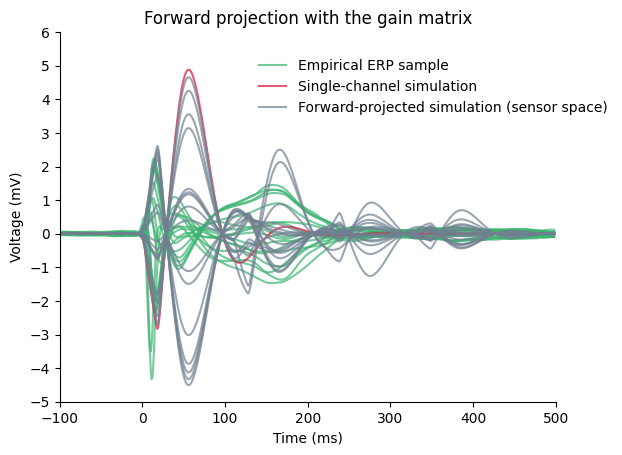

In [14]:
G_demo, _ = infr.compute_gain_matrix_jax(example_avg_erp, weight_by_variance=weight_by_variance_gain)
sim_demo_full = jrm.simulate_erp_temporal(ts, input_params, free_params={}, noise_params=(0., 0., 15))
sim_demo = np.asarray(sim_demo_full[::ds_sim])
forward_demo = infr.compute_forward_solution_multimode_jax(sim_demo, G_demo).T

print('single-channel simulation:', sim_demo.shape, '| gain matrix:', G_demo.shape, '| forward-projected:', forward_demo.shape)

y_max = np.ceil(max(np.abs(example_avg_erp).max(), np.abs(sim_demo).max(), np.abs(forward_demo).max()))

fig, ax = plt.subplots()
ax.plot(time_vec, example_avg_erp, color='mediumseagreen', alpha=0.7, lw=1.5, label='Empirical ERP sample')
ax.plot(ts[::ds_sim], sim_demo, c='crimson', alpha=0.7, lw=1.5, label='Single-channel simulation')
ax.plot(ts[::ds_sim], forward_demo, c='slategray', alpha=0.7, lw=1.5, label='Forward-projected simulation (sensor space)')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(-100, 500), yticks=[-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6])
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (mV)')
ax.set_title('Forward projection with the gain matrix')
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 0.85))
plt.show()

### Choosing the delay range (dmin, dmax)

For the above forward projection we chose `dmax=330`. Meaning that the different copies of the simulation get delays of 0, 110, 220 and 330 ms. 


A priori there is no reason why we should choose this value for `dmax`. Therefore in this subsection we investigate what the best values of `dmax` are, and while we're at it, whether the `weight_by_variance` choice above (needed structurally for Pipelines 1 to 4, see "Gain matrix invariance" under Pipeline 1) costs us anything in this specific decision.

We try a big set of candidate ranges, simulate the signal through both the unweighted and the weighted gain matrix (but only for `n_sweep` simulations, otherwise it would take too long), and plot some characteristic quantities for each. 

This takes 30 min to run, therefore we introduced the boolean `regenerate_delay_sweep`, if `False` the results are just loaded from storage.

In [15]:
variant_style = {'unweighted': dict(color='slategray', ls='--', marker=None),
                  'weighted': dict(color='steelblue', ls='-', marker=None)}

In [16]:
# candidate (dmin, dmax) pairs to compare, in ms.
delay_candidates = [(0, d) for d in [3, 6, *range(9, 801, 3)]]
n_sweep = min(100, sim_array.shape[0])

regenerate_delay_sweep = False  # True: rerun the full sweep (slow). False: load the saved result from sim_path
delay_sweep_path = os.path.join(sim_path, 'delay_sweep.pkl')

if regenerate_delay_sweep:
    sim_array_sweep = jnp.array(sim_array.to_numpy()[:n_sweep])
    theta_sweep = theta[:n_sweep]

    G_demo_unweighted, _ = infr.compute_gain_matrix_jax(example_avg_erp, weight_by_variance=False)
    gain_variants = {'unweighted': G_demo_unweighted, 'weighted': G_demo}

    # flattened so one progress bar covers the full sweep
    combos = [(variant_name, G_variant, dmin_c, dmax_c)
              for variant_name, G_variant in gain_variants.items()
              for dmin_c, dmax_c in delay_candidates]

    delay_sweep_rows = []
    pci_arrays = {}  # (gain_variant, dmax) -> raw per-simulation PCIst array, used by the distribution plot below
    pbar = tqdm(combos, desc='Delay range sweep')
    for variant_name, G_variant, dmin_c, dmax_c in pbar:
        pbar.set_postfix(variant=variant_name, dmax=dmax_c)
        Y_sweep = infr.compute_forward_solution_multimode_jax_batch(sim_array_sweep, G_variant,
                                                                      dmin=dmin_c, dmax=dmax_c, batch_size=100)
        pci_sweep = pcist.compute_pci_batch_chunked(Y_sweep, time_vec, batch_size=20, full_return=False,
                                                      n_components=Y_sweep.shape[1], **pci_pars)
        pci_sweep = np.asarray(pci_sweep)
        pci_arrays[(variant_name, dmax_c)] = pci_sweep

        overlap = infr.compute_kde_overlap(pci_sweep, emp_all)
        row = dict(gain_variant=variant_name, dmin=dmin_c, dmax=dmax_c, mean=pci_sweep.mean(), std=pci_sweep.std(),
                   kde_overlap=overlap)
        for i, p in enumerate(prm_names):
            row[f'corr_{p}'] = np.corrcoef(theta_sweep[:, i].numpy(), pci_sweep)[0, 1]
        delay_sweep_rows.append(row)

    delay_sweep_df = pd.DataFrame(delay_sweep_rows)

    with open(delay_sweep_path, 'wb') as f:
        pickle.dump({'delay_sweep_df': delay_sweep_df, 'pci_arrays': pci_arrays}, f)
    print(f'sweep computed and saved to {delay_sweep_path}')
else:
    if not os.path.exists(delay_sweep_path):
        raise FileNotFoundError(f'No saved sweep at {delay_sweep_path}, set regenerate_delay_sweep=True once to create it')
    with open(delay_sweep_path, 'rb') as f:
        saved = pickle.load(f)
    delay_sweep_df = saved['delay_sweep_df']
    pci_arrays = saved['pci_arrays']
    print(f'loaded saved sweep from {delay_sweep_path}, {len(delay_sweep_df)} rows')

loaded saved sweep from /home/milchris/EPIC/Final version all combined/input/JR_EC_1000/delay_sweep.pkl, 532 rows


For a given `dmax` value the calculated PCIst values of the 16 channel simulation have a given distribution.

We would like this simulated PCIst distribution to encompass the emperical PCIst disitrubution, because only then the SBI algorithm can work properly.

To test this for the different `dmax` values, we can plot the overlap between simulated and empirical PCIst directly, one curve per gain matrix variant, using the inner product between both distributions.

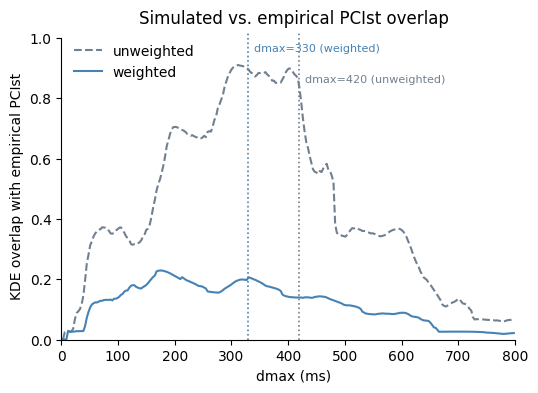

In [82]:
dmax_check = 330
dmax_check_unweighted = 420

fig, ax = plt.subplots(figsize=(6, 4))
for variant_name, sub_df in delay_sweep_df.groupby('gain_variant'):
    sub_df = sub_df.sort_values('dmax')
    ax.plot(sub_df['dmax'], sub_df['kde_overlap'], label=variant_name, **variant_style[variant_name])
ax.axvline(dmax_check, color='steelblue', linestyle=':', linewidth=1.2, zorder=0)
ax.text(dmax_check + 10, 0.98, f'dmax={dmax_check} (weighted)', color='steelblue', fontsize=8, va='top')
ax.axvline(dmax_check_unweighted, color='slategray', linestyle=':', linewidth=1.2, zorder=0)
ax.text(dmax_check_unweighted + 10, 0.88, f'dmax={dmax_check_unweighted} (unweighted)', color='slategray', fontsize=8, va='top')
ax.set_xlabel('dmax (ms)')
ax.set_ylabel('KDE overlap with empirical PCIst')
ax.set_title('Simulated vs. empirical PCIst overlap')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 820), xticks=[0, 100, 200, 300, 400, 500, 600, 700, 800],
                             ylim=(0, 1.02), yticks=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
plotting.dedupe_legend(ax, frameon=False)
plt.show()


Both curves start the same way, rising fast until about dmax=50 then flattening out until roughly dmax=150. From there the two curves diverge. Unweighted keeps climbing steeply and hits a clear peak around dmax=312, close to 0.9, dips slightly, then rises once more to a smaller second peak near dmax=400, after which it drops off steadily for the rest of the sweep.

Weighted highest point sits earlier, around dmax=190, reaching about 0.23, then dips a bit before climbing back to a second, slightly lower peak around dmax=330 (about 0.20). After that it declines gradually for the rest of the sweep.

Overall unweighted has by far the better overlap, close to 0.9 at its peak against weighted's best of roughly 0.23. But as we will see later in the plot, the unweigthed distribution is not wide enough to encompass the whole emperical disitribution.

Because of this, we will have to rescale the simulated PCIst distributions to make it better match the emperical range (see further), regardless of which dmax we end up with.

With the rescale established as necessary, we can now look at the other two quantities to actually pick the best dmax values: 
- The spread of the PCIst values (which we want to maximize)
- The parameter sensitivity (which we want to maximize)

We plot one curve per gain matrix variant so the two are directly comparable.

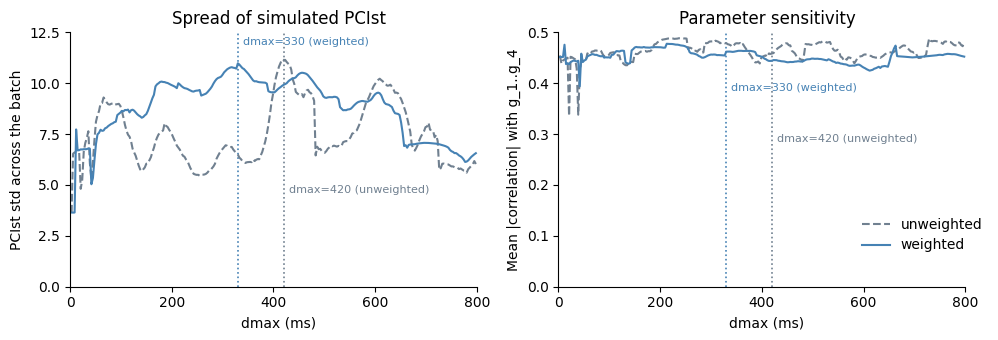

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for variant_name, sub_df in delay_sweep_df.groupby('gain_variant'):
    sub_df = sub_df.sort_values('dmax')
    axes[0].plot(sub_df['dmax'], sub_df['std'], label=variant_name, **variant_style[variant_name])
axes[0].axvline(dmax_check, color='steelblue', linestyle=':', linewidth=1.2, zorder=0)
axes[0].text(dmax_check + 10, 12.25, f'dmax={dmax_check} (weighted)', color='steelblue', fontsize=8, va='top')
axes[0].axvline(dmax_check_unweighted, color='slategray', linestyle=':', linewidth=1.2, zorder=0)
axes[0].text(dmax_check_unweighted + 10, 5.0, f'dmax={dmax_check_unweighted} (unweighted)', color='slategray', fontsize=8, va='top')
axes[0].set_xlabel('dmax (ms)')
axes[0].set_ylabel('PCIst std across the batch')
axes[0].set_title('Spread of simulated PCIst')
plotting.modify_axis_spines(axes[0], which=['x', 'y'], xlim=(0, 820), xticks=[0, 200, 400, 600, 800], ylim=(0, 12.5))
corr_cols = [f'corr_{p}' for p in prm_names]
for variant_name, sub_df in delay_sweep_df.groupby('gain_variant'):
    sub_df = sub_df.sort_values('dmax')
    mean_abs_corr = sub_df[corr_cols].abs().mean(axis=1)
    axes[1].plot(sub_df['dmax'], mean_abs_corr, label=variant_name, **variant_style[variant_name])
axes[1].axvline(dmax_check, color='steelblue', linestyle=':', linewidth=1.2, zorder=0)
axes[1].text(dmax_check + 10, 0.4, f'dmax={dmax_check} (weighted)', color='steelblue', fontsize=8, va='top')
axes[1].axvline(dmax_check_unweighted, color='slategray', linestyle=':', linewidth=1.2, zorder=0)
axes[1].text(dmax_check_unweighted + 10, 0.3, f'dmax={dmax_check_unweighted} (unweighted)', color='slategray', fontsize=8, va='top')
axes[1].set_xlabel('dmax (ms)')
axes[1].set_ylabel('Mean |correlation| with g_1..g_4')
axes[1].set_title('Parameter sensitivity')
plotting.modify_axis_spines(axes[1], which=['x', 'y'], xlim=(0, 820), xticks=[0, 200, 400, 600, 800], ylim=(0, 0.5))
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 0.4))
fig.tight_layout()
plt.show()


Panel 1 (spread): The unweigthed curve is noisy, with several local ups and downs rather than one clean shape, with its overall highest point is at dmax=420. Weigthed has a general increase untill dmax=330, after which it slowly drops down.

Panel 2 (parameter sensitivity): both curves are jumpy at very low dmax, then settle down. From roughly dmax=150 onward, unweighted and weighted sit super close and both hover in a flat band around 0.43 to 0.49 out to dmax=800.

Because panel 2 is nearly constant, we will base our choice on panel 1.

Using all of this information, we find that the best dmax value for weigthed is 330, while the best dmax value for unweigthed is 420. Therefore we settle with two different dmax values: one for weigthed gain matrices and one for unweigthed gain matrices.

These 2 values are the dmax values with the highest spread.

For the biggest part of this notebook (except for one subsection, see further) we will keep using the weighted gain matrix. Because only a weighted gain matrix breaks the PCIst invariance that Pipelines 1 to 4 rely on for their condition, subject and trial encoding to carry any information at all (see "Gain matrix invariance" under Pipeline 1). dmax=330 gets stored below as DMAX_CHOSEN and used explicitly wherever the delay range matters for the rest of this notebook.

In [84]:
DMIN_CHOSEN = 0
DMAX_CHOSEN = 330  # ms. Value used for the weighted gain matrices throughout this notebook.

### PCIst distribution by dmax, weighted vs. unweighted

`pci_arrays` from the sweep above holds the actual per-simulation PCIst values, not just the summary stats, so we can look at the full simulated distribution for any tested `dmax`, weighted and unweighted side by side, against the empirical PCIst distribution. 

In [20]:
dmax_options = sorted({dmax_c for _, dmax_c in delay_candidates})

def plot_pci_distribution(dmax_choice):
    fig, ax = plt.subplots(figsize=(7, 3))
    sns.kdeplot(pci_arrays[('unweighted', dmax_choice)], ax=ax, fill=True, color='slategray', alpha=0.4,
                label='Simulated (unweighted)', cut=0, bw_adjust=0.25)
    sns.kdeplot(pci_arrays[('weighted', dmax_choice)], ax=ax, fill=True, color='steelblue', alpha=0.4,
                label='Simulated (weighted)', cut=0, bw_adjust=0.25)
    sns.kdeplot(emp_all, ax=ax, fill=True, color='crimson', alpha=0.5, label='Empirical', cut=0, bw_adjust=0.25)
    ax.set_xlabel('PCIst')
    ax.set_ylabel('Density')
    ax.set_title(f'Simulated vs. empirical PCIst coverage (dmax = {dmax_choice} ms)')
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 200))
    plotting.dedupe_legend(ax, frameon=False)
    plt.show()

dmax_slider = widgets.SelectionSlider(options=dmax_options, value=DMAX_CHOSEN if DMAX_CHOSEN in dmax_options else dmax_options[0],
                                       description='dmax (ms):', continuous_update=True)
plot_output = widgets.Output()

def on_dmax_change(change):
    if change['name'] == 'value':
        with plot_output:
            plot_output.clear_output(wait=True)
            plot_pci_distribution(change['new'])

dmax_slider.observe(on_dmax_change, names='value')
display(dmax_slider, plot_output)

with plot_output:
    plot_pci_distribution(dmax_slider.value)

SelectionSlider(description='dmax (ms):', index=109, options=(3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39,…

Output()

As already seen in the overlap plot, the overlap between unweigthed and empirical is better than between weigthed and emperical. But in neither case does the simulated distribution encompass fully the emperical distribution. And then it is possible that the neural network of the SBI will be asked about inputs it essentially never saw during training. 

Solution: we rescaling the simulated PCIst disitributions.

From now on we will work further only with the weigthed simulations, further in this notebook we will also revisit the unweigthed simulations.

### Performing the whole batch of 16 channels simulations

Now we perform the big batch of 1000 simulations at the chosen dmax=330 ms, and calculate its PCIst values.

In [80]:
Y_batch_check = infr.compute_forward_solution_multimode_jax_batch(jnp.array(sim_array.to_numpy()), G_demo,
                                                                    dmin=DMIN_CHOSEN, dmax=DMAX_CHOSEN, batch_size=100)
pci_batch_check = pcist.compute_pci_batch_chunked(Y_batch_check, time_vec, batch_size=20, full_return=False,
                                                    n_components=Y_batch_check.shape[1], **pci_pars)
pci_batch_check = np.asarray(pci_batch_check)

# emp_all already computed above, right when the data got loaded, reused here as is

print(f'simulated PCIst range:  {pci_batch_check.min():.1f} to {pci_batch_check.max():.1f} '
      f'(median {np.median(pci_batch_check):.1f})')
print(f'empirical PCIst range:  {emp_all.min():.1f} to {emp_all.max():.1f} '
      f'(median {np.median(emp_all):.1f})')

simulated PCIst range:  11.7 to 53.4 (median 26.6)
empirical PCIst range:  28.8 to 112.8 (median 60.0)


Again we can plot the overlap with the emperical PCIst range.

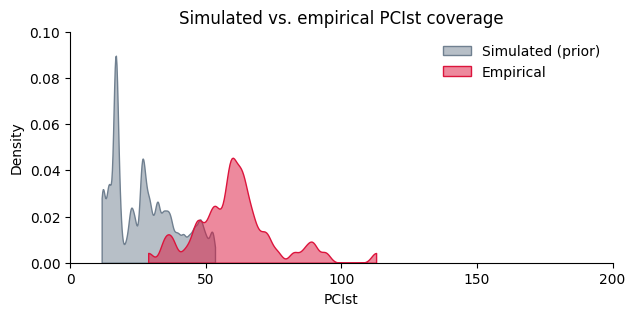

In [81]:
fig, ax = plt.subplots(figsize=(7, 3))
sns.kdeplot(pci_batch_check, ax=ax, fill=True, color='slategray', alpha=0.5, label='Simulated (prior)', cut=0, bw_adjust=0.25)
sns.kdeplot(emp_all, ax=ax, fill=True, color='crimson', alpha=0.5, label='Empirical', cut=0, bw_adjust=0.25)
ax.set_xlabel('PCIst')
ax.set_ylabel('Density')
ax.set_title('Simulated vs. empirical PCIst coverage')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 200))
plotting.dedupe_legend(ax, frameon=False)
plt.show()

These distributions don't really overlap, therefore we will rescale the simulated distribution.

### Rescaling simulated PCIst to cover the empirical range

The rescaling is a simple linear transform, `PCIst_rescaled = a * PCIst_sim + b`, a and b are set such that after rescaling the lowest simulated PCIst value sits below the lowest empirical value, and the highest simulated value sits above the highest empirical value. 

Every gain matrix used later on gives its own raw PCIst distribution, on its own scale: Pipeline 0's grand average, Pipeline 1's wake/anesthesia pair, Pipeline 2's four condition specific matrices, and the unweighted one used only in the sanity check near the end. So each one gets its own separate rescale.

Now we will rescale in the case of one global gain matrix (used for Pipeline 0).

In [94]:
# fraction of the empirical range added on each side. Raise this to push the simulated range further past the empirical one
#pcist_rescale_margin_low = 0.05
#pcist_rescale_margin_high = 0.85
#a_weighted, b_weighted = infr.fit_pcist_rescale(pci_batch_check, emp_all, margin_lo=pcist_rescale_margin_low, margin_hi=pcist_rescale_margin_high)

# The a and b values were found previously using the above method.
a_weighted, b_weighted = 2.1, 2.5
print(f'weighted rescale: PCIst_rescaled = {a_weighted:.2f} * PCIst {b_weighted:.2f}')

pci_batch_check_rescaled = infr.apply_pcist_rescale(pci_batch_check, a_weighted, b_weighted)
print(f'rescaled simulated PCIst range: {pci_batch_check_rescaled.min():.1f} to {pci_batch_check_rescaled.max():.1f}')
print(f'empirical PCIst range:          {emp_all.min():.1f} to {emp_all.max():.1f}')

weighted rescale: PCIst_rescaled = 2.10 * PCIst 2.50
rescaled simulated PCIst range: 27.0 to 114.7
empirical PCIst range:          28.8 to 112.8


Now we can plot the weigthed simulated PCIst value distribution vs. the empirical PCIst value distribution.

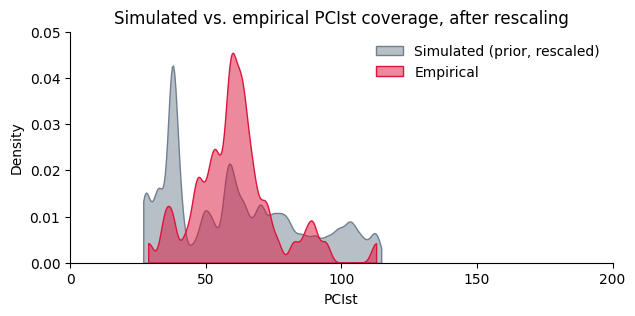

In [95]:
fig, ax = plt.subplots(figsize=(7, 3))
sns.kdeplot(pci_batch_check_rescaled, ax=ax, fill=True, color='slategray', alpha=0.5, label='Simulated (prior, rescaled)', cut=0, bw_adjust=0.25)
sns.kdeplot(emp_all, ax=ax, fill=True, color='crimson', alpha=0.5, label='Empirical', cut=0, bw_adjust=0.25)
ax.set_xlabel('PCIst')
ax.set_ylabel('Density')
ax.set_title('Simulated vs. empirical PCIst coverage, after rescaling')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 200))
plotting.dedupe_legend(ax, frameon=False)
plt.show()

The rescaled simulated range now encompasses the empirical one on both ends.

`a_weighted, b_weighted` are the two numbers that matter from here, but only for Pipeline 0: this whole section used Pipeline 0's own gain matrix (the grand average one), so this rescale is exactly what Pipeline 0 needs, and it gets reused directly in its section below without refitting anything. 

Pipeline 1's two gain matrices and Pipeline 2's four are each built from different, condition specific ERP averages, which gives each of them a different raw PCIst distribution, so a rescale fit on Pipeline 0's distribution doesn't necessarily line their simulated ranges up with the empirical one. Rather than forcing the same numbers everywhere, Pipelines 1 and 2 each get their own `a_p1, b_p1` and `a_p2, b_p2` further down. Within a pipeline it stays one shared rescale across every condition that pipeline covers though, so the relative differences between conditions inside one pipeline are not touched by rescaling, only the overall location and spread. The unweighted sanity check further down already does this for its own gain matrix too (`a_unweighted, b_unweighted`).

Empirical PCIst values themselves are never touched anywhere. The whole point is bringing each simulated distribution out to where the real data already sits, not the other way around.

## Pipelines: introduction

The same simulations and the same prior are reused for every pipeline in this notebook,
what changes is how much detail goes into the gain matrix (and therefore how
much conditioning information the SNPE estimator sees):

| Pipeline | Gain matrices | Extra encoding columns | What it tests |
|---|---|---|---|
| P0 | 1, shared across everything | none | baseline, does PCIst carry any information about `g_i` at all |
| P1 | 2, one wake, one anesthesia (pooled) | 1 binary flag | does the wake/anesthesia distinction show up once gain matrices differ by state |
| P2 | 4, one per condition (wake, keta, prop, sevo) | 4-way one-hot | same question, but letting each anesthetic have its own spatial signature |
| P3 | 1 per subject per condition | 4-way one-hot + per-subject one-hot | fully personalized gain matrices, still on trial-averaged data |
| P4 | 1 per subject per condition per trial | 4-way one-hot + per-subject one-hot + per-trial one-hot | same as P3 but on individual trials instead of the trial average |

Each pipeline trains its own SNPE estimator (the encoding width is different each time, so the density estimators are not interchangeable), then samples $p(\theta \mid \text{PCIst}, \text{encoding})$ for every empirical subject/condition (and trial, for P4). P0 to P2 use one shared gain matrix
computation each, so we can go straight to training, and are the ones run below. P3 and P4 loop per subject (and per trial), which is also where most
of their runtime goes, so they are kept in the appendix at the end instead.

Every gain matrix below is computed with `weight_by_variance=True`, not the unit-norm default. Pipeline 1 explains why (short version: with the default setting PCIst turns out to be exactly independent of which gain matrix is used, so none of P1 to P4's encoding columns would carry any real information).

As already stated the rescaling of the simulated PCist values gets redone starting from Pipeline 1.

A couple of settings are shared across all five pipelines (P0 to P2 below, P3/P4 in the appendix):

In [96]:
normalize_features = False     # Alternative to currently used rescaling:
                               # scale PCIst values to [0, 1] before training (simulated: min/max of the simulated set;
                               # empirical: divided by one shared global max, see below, so relative differences between
                               # anesthesia types are preserved rather than each dataset getting its own scale)
normalize_posteriors = False   # purely visual: scale each posterior's g_i samples to [0, 1] so different g_i are comparable on one plot
num_samples = 2000            # posterior samples drawn per subject/condition
num_components = 4            # gain matrix rank, matches the cumulative-variance check above

# weight_by_variance_gain already set to True above, right before "Gain matrix: concept",
estimator_type = 'maf'
forward_chunks = 100          # batch size for the gain-matrix forward projection (jax, GPU)
pci_chunks = 20               # batch size for PCIst itself, the more memory-hungry of the two on a 4GB GPU

anes_keys = ANES_TYPES
posterior_dims = ('subject', 'condition', 'theta', 'sample')

## Pipeline 0: unified gain inference

The simplest case: one gain matrix (from the grand average ERP across every subject and condition) used for everything.

First we plot this average ERP:

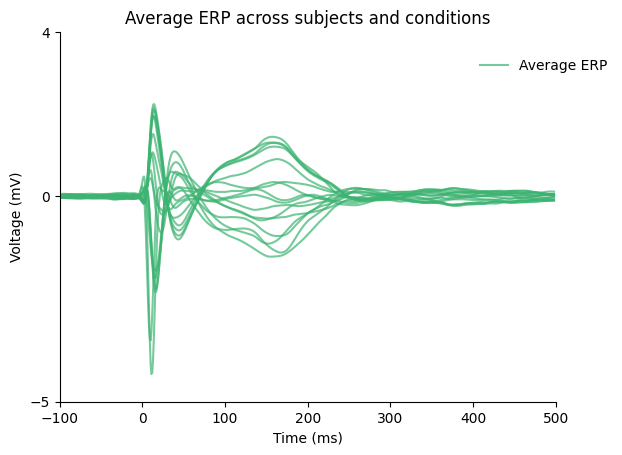

In [97]:
pipeline = 0

avg_erp = combined_erp.mean(dim=['subject']).mean(dim=['condition']).dropna('region').to_numpy()

fig, ax = plt.subplots()
ax.plot(time_vec, avg_erp, color='mediumseagreen', alpha=0.7, lw=1.5, label='Average ERP')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(-100, 500), yticks=[-5, 0, 4])
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (mV)')
ax.set_title('Average ERP across subjects and conditions')
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 0.85))
plt.show()

Now we compute the gain matrix, perform the 16 channel simulations and calculate its PCIst values, after which we rescale these:

In [98]:
gains_p0 = infr.compute_shared_gain(combined_erp, anes_keys=anes_keys, pipeline=pipeline, num_components=num_components,
                                     weight_by_variance=weight_by_variance_gain)

theta_arr_p0, feature_array_p0 = infr.make_sbi_dataset(
    sim_array.to_numpy(), theta, gains_p0, time_vec, pci_pars, pipeline,
    forward_chunks=forward_chunks, pci_chunks=pci_chunks)

# Rescaling the simulated PCIst, see "Rescaling simulated PCIst"
feature_array_p0[:, 0] = infr.apply_pcist_rescale(feature_array_p0[:, 0], a_weighted, b_weighted)
print(theta_arr_p0.shape, feature_array_p0.shape)  # expect (num_sim, num_params), (num_sim, 1)

torch.Size([1000, 4]) torch.Size([1000, 1])


In [99]:
x_features_p0 = feature_array_p0.numpy()

if normalize_features:
    scaler_p0 = preprocessing.MinMaxScaler()
    x_features_p0[:, 0:1] = scaler_p0.fit_transform(x_features_p0[:, 0:1])

x_features_p0 = torch.as_tensor(x_features_p0.astype(np.float32))
theta_tensor_p0 = torch.as_tensor(theta_arr_p0)

Now plot the correlation between PCIst and the 4 g-parameters.

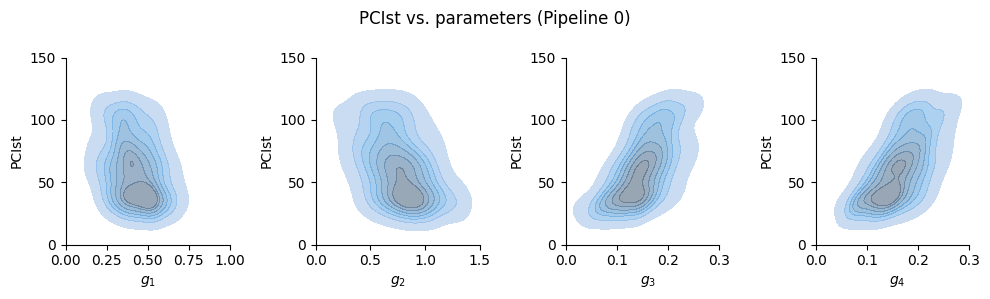

In [246]:
# manually set (lo, hi) and tick list per parameter.
xlims_p0 = [(0, 1), (0, 1.5), (0, 0.32), (0, 0.32)]
xticks_p0 = [(0, 0.25, 0.5, 0.75, 1), (0, 0.5, 1.0, 1.5), (0, 0.1, 0.2, 0.3), (0, 0.1, 0.2, 0.3)]

pci_values_p0 = x_features_p0[:, 0]
plotting.plot_pci_vs_params(
    theta_arr_p0, pci_values_p0, prm_names, param_labels,
    title='PCIst vs. parameters (Pipeline 0)',
    mode='density',
    xlim=xlims_p0,                 
    xticks=xticks_p0,                
    yticks=[0, 50, 100, 150],
    ylim=(0, 150))    
plt.show()

There are different correlations visible between PCIst value and g-parameters:

- `g_1`: Extremely weak negative correlation
- `g_2`: Weak negative correlation
- `g_3`: Positive correlation
- `g_4`: Positive correlation

This is important to remember for later

Now train the SNPE estimator on the simulated (theta, PCIst) pairs.

In [101]:
inference_nn_p0 = sbi.inference.SNPE(prior, density_estimator=estimator_type, device=device)
posterior_estimator_p0 = inference_nn_p0.append_simulations(theta_tensor_p0, x_features_p0).train()
posterior_p0 = sbi.inference.DirectPosterior(posterior_estimator_p0, prior)

 Neural network successfully converged after 256 epochs.

### Synthetic validation: parameter recovery check

Now we sample a random "true" parameter set from the simulations, feed the posterior its PCIst value, and check whether the posterior actually recovers something close to the true value.

In [102]:
seed_p0_validation = 0  # fixed seed, so the "true" parameter draw below stays the same every rerun
rng_p0_validation = np.random.default_rng(seed_p0_validation)

theta_true_ind = rng_p0_validation.integers(len(theta_tensor_p0))
theta_true_sample = theta_tensor_p0[theta_true_ind, :]
theta_true_feat = x_features_p0[theta_true_ind, :]
print(f"Sampled g-parameters: {theta_true_sample} \nSampled PCIst value: {theta_true_feat}")

Sampled g-parameters: tensor([0.5485, 1.0476, 0.1543, 0.1407]) 
Sampled PCIst value: tensor([37.7994])


Given this PCIst value, we sample the g-parameters from the posterior $p(\theta \mid \text{PCIst})$ and calculate the mean of these samples:

In [103]:
theta_pred = posterior_p0.sample((num_samples,), x=theta_true_feat).numpy().squeeze()
theta_pred_mean = theta_pred.mean(0)

  0%|          | 0/2000 [00:00<?, ?it/s]

Now we can plot the prior and posterior.

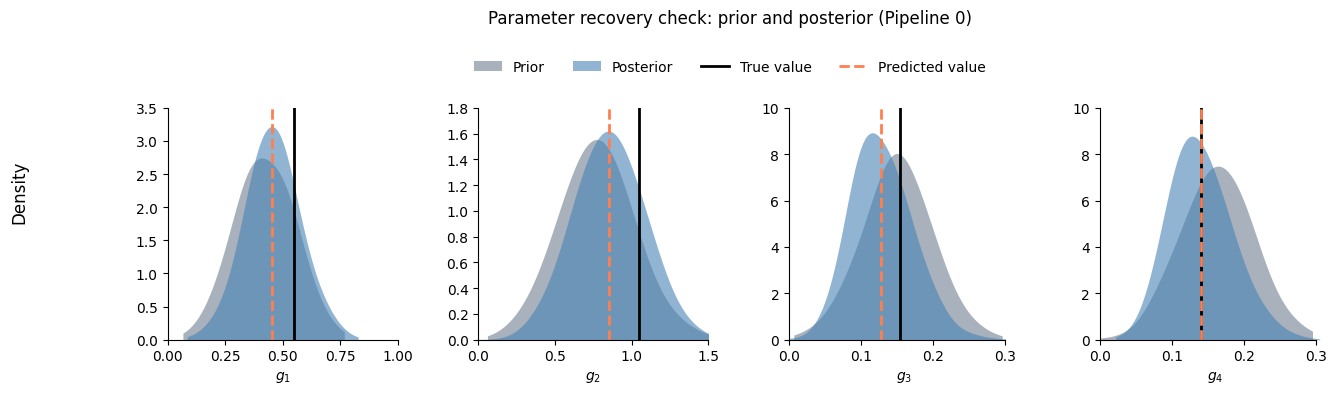

In [104]:
fig, axes = plt.subplots(1, num_params, figsize=(15, 3.8))
for i, ax in enumerate(axes):
    sns.kdeplot(theta_tensor_p0[:, i].numpy(), ax=ax, fill=True, linewidth=0, color='slategray', alpha=0.6, label='Prior', cut=0, bw_adjust=2)
    sns.kdeplot(theta_pred[:, i], ax=ax, fill=True, linewidth=0, color='steelblue', alpha=0.6, label='Posterior', cut=0, bw_adjust=2)
    ax.axvline(theta_true_sample.numpy()[i], c='k', ls='-', lw=2, label='True value')
    ax.axvline(theta_pred_mean[i], c='coral', ls='--', lw=2, label='Predicted value')
    ax.set_xlabel(param_labels[prm_names[i]])
    ax.set_ylabel('')

    if xlims_p0[i] is not None:
        xlim = xlims_p0[i]
    else:
        lo = min(theta_tensor_p0[:, i].numpy().min(), theta_pred[:, i].min(), theta_true_sample.numpy()[i])
        hi = max(theta_tensor_p0[:, i].numpy().max(), theta_pred[:, i].max(), theta_true_sample.numpy()[i])
        pad = 0.1 * (hi - lo)
        xlim = (lo - pad, hi + pad)

    xticks = xticks_p0[i] if xticks_p0[i] is not None else ()
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=xlim, xticks=xticks)
handles, labels = axes[0].get_legend_handles_labels()
fig.supylabel('Density', x=0.02)
fig.suptitle('Parameter recovery check: prior and posterior (Pipeline 0)', y=0.98)
fig.legend(handles, labels, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 0.88), ncol=4)
fig.subplots_adjust(top=0.72, wspace=0.35)
plt.show()

This doesn't look super good, but keep in mind that in this Notebook the goal is not being able to find precise g parameter values for a given ERP signal, but to find correlations. And we see that the posterior above indeed moves towards the true value opposed to the prior, this is a good sign.

Now let's look at what this predicted parameter set actually looks like as a waveform, not just as a marginal distribution. 

Two versions: the raw single channel model output first, then the same true vs. predicted comparison after the gain matrix forward projection, i.e. the 16 channel sensor space PCIst actually gets computed in.

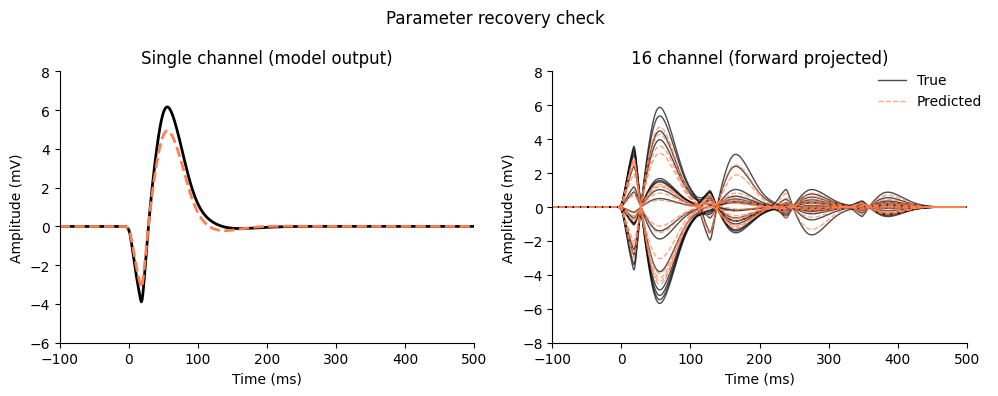

In [105]:
free_params_true = dict(zip(prm_names, theta_true_sample.numpy()))
free_params_pred = dict(zip(prm_names, theta_pred_mean))

# noise off here (0., 0., ...): we want to see the deterministic shape difference that
# actually follows from theta, not one random noise draw obscuring it
erp_true = jrm.simulate_erp_temporal(ts, input_params, free_params=free_params_true, noise_params=(0., 0., 15))
erp_pred = jrm.simulate_erp_temporal(ts, input_params, free_params=free_params_pred, noise_params=(0., 0., 15))

# downsample to the same resolution the gain matrix and PCIst pipeline actually work at,
# same as sim_demo earlier in the notebook
erp_true_ds = np.asarray(erp_true)[::ds_sim]
erp_pred_ds = np.asarray(erp_pred)[::ds_sim]

# pipeline 0 has one shared gain matrix (gains_p0['wake'] and gains_p0['anes'] are
# the same matrix, see compute_shared_gain), so it doesn't matter which key we grab here
G_p0 = list(gains_p0.values())[0]
sensor_true = infr.compute_forward_solution_multimode_jax(erp_true_ds, G_p0).T
sensor_pred = infr.compute_forward_solution_multimode_jax(erp_pred_ds, G_p0).T

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(ts[::ds_sim], erp_true_ds, lw=2, c='k', label='True')
axes[0].plot(ts[::ds_sim], erp_pred_ds, lw=2, ls='--', c='coral', label='Predicted')
axes[0].set_xlabel('Time (ms)')
axes[0].set_ylabel('Amplitude (mV)')
axes[0].set_title('Single channel (model output)')
plotting.modify_axis_spines(axes[0], which=['x', 'y'], xlim=(float(ts.min()), 500))

axes[1].plot(ts[::ds_sim], sensor_true, lw=1, alpha=0.7, c='k', label='True')
axes[1].plot(ts[::ds_sim], sensor_pred, lw=1, alpha=0.7, ls='--', c='coral', label='Predicted')
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('Amplitude (mV)')
axes[1].set_title('16 channel (forward projected)')
plotting.modify_axis_spines(axes[1], which=['x', 'y'], xlim=(float(ts.min()), 500))

fig.suptitle('Parameter recovery check')
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 0.85))
fig.tight_layout()
plt.show()

This also doesn't look good. But again, we don't want to end up with an exact fit to the original (emperical) signal in this Notebook.

### Posterior on the empirical data (trial-averaged)

Now the actual point of training this network: feed it the empirical PCIst values and get a posterior over `g_i` for every subject and condition.
`emp_feature_dict` (loaded once here, reused by pipelines 1 to 3 below) gets defined here for the first time.

In [106]:
emp_feature_dict = {anes: pcist_datasets[anes] for anes in anes_keys}
global_emp_max = float(np.max(np.concatenate([emp_feature_dict[a].values.ravel() for a in anes_keys])))
print('global empirical PCIst max:', global_emp_max)

emp_posteriors_p0 = {}

for anes_name in anes_keys:
    emp_array = emp_feature_dict[anes_name].values.astype(np.float32).reshape(-1, 1)
    if normalize_features:
        # same scaler used to fit_transform the simulated PCIst above, so the
        # empirical values land on the exact scale the network was trained on
        emp_array = scaler_p0.transform(emp_array)

    emp_tensor = torch.tensor(emp_array, dtype=torch.float32)
    theta_samples = posterior_p0.sample_batched(sample_shape=(num_samples,), x=emp_tensor, show_progress_bars=False)

    n_subjects = emp_feature_dict[anes_name].sizes['subject']
    n_conditions = emp_feature_dict[anes_name].sizes['condition']
    theta_samples = theta_samples.permute(1, 2, 0).reshape(n_subjects, n_conditions, num_params, num_samples)

    emp_posteriors_p0[anes_name] = xr.DataArray(
        theta_samples.numpy(), dims=posterior_dims,
        coords=dict(subject=emp_feature_dict[anes_name].subject, condition=emp_feature_dict[anes_name].condition, theta=prm_names))

    print(f'{anes_name}: posterior shape {emp_posteriors_p0[anes_name].shape}')


global empirical PCIst max: 112.83421325683594
keta: posterior shape (8, 2, 4, 2000)
prop: posterior shape (9, 2, 4, 2000)
sevo: posterior shape (10, 2, 4, 2000)


In [107]:
if normalize_posteriors:
    all_posteriors_p0 = xr.concat(list(emp_posteriors_p0.values()), dim='anes')
    global_param_max_p0 = all_posteriors_p0.max(('anes', 'subject', 'condition', 'sample'))
    for anes_name in anes_keys:
        emp_posteriors_p0[anes_name] = emp_posteriors_p0[anes_name] / global_param_max_p0

for anes_name in anes_keys:
    out_dir = f'output/{pipeline}_{num_sim}/{anes_name}'
    os.makedirs(out_dir, exist_ok=True)
    emp_posteriors_p0[anes_name].to_netcdf(out_dir + f'/theta_posteriors_{pipeline}_{anes_name}.nc')

theta_df_p0 = infr.pool_posteriors(emp_posteriors_p0)

### Plotting the Pipeline 0 posteriors

Now we plot the parameter posteriors, which we got from training the neural network via pipeline 0 (single gain matrix projected 1 channel simulation into 16 channel simulation, after which we calculated its PCIst value) and plugging the empirical PCIst values into it.

We have different options for plots, in the first plot we focus on the `dataset_to_plot` data, and in the second on the `sel_param` parameter, while in the last plot we plot everything together.

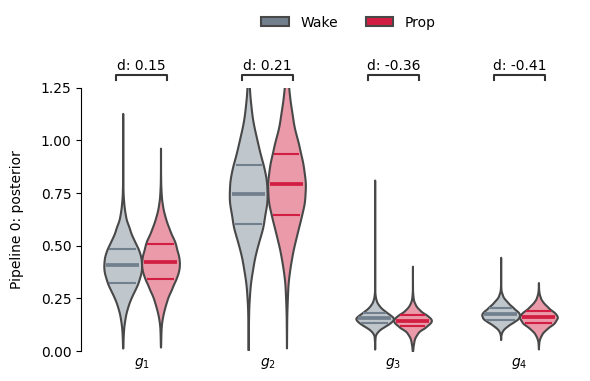

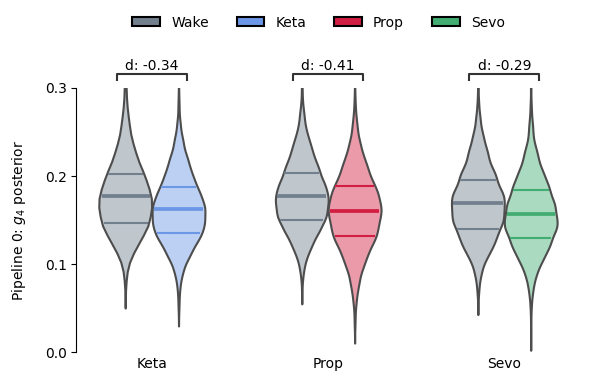

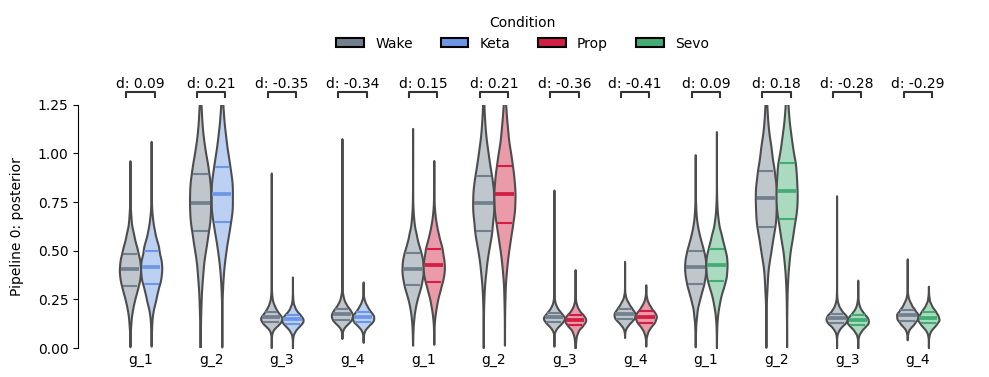

In [248]:
dataset_to_plot = 'prop'
sel_param = 'g_4'

fig1, ax1 = plt.subplots(figsize=(6, 4))
plotting.plot_single_dataset_comparison(fig1, ax1, theta_df_p0, dataset_to_plot, plotting.DATASET_PALETTES[dataset_to_plot],
                                         lw=1.5, legend=True, saturation=0.9, custom_labels=list(param_labels.values()),
                                         ylabel='Pipeline 0: posterior', width=0.6, labelpad=12, lgd_loc=(0.35, 1.2),
                                         theta_column='theta_label',
                                         y_lim=(0, 1.25), y_ticks=(0, 0.25, 0.50, 0.75, 1, 1.25))

fig2, ax2 = plt.subplots(figsize=(6, 4))
plotting.plot_parameter_across_datasets(fig2, ax2, theta_df_p0, sel_param, anes_keys, plotting.DATASET_PALETTES,
                                         lw=1.5, legend=True, saturation=0.9,
                                         ylabel=f'Pipeline 0: {param_labels[sel_param]} posterior',
                                         width=0.6, labelpad=12, lgd_loc=(0.1, 1.2), theta_column='theta_label',
                                         y_lim=(0, 0.3), y_ticks=(0, 0.1, 0.2, 0.3))

fig3, ax3 = plt.subplots(figsize=(10, 4))
plotting.plot_pooled_posteriors(fig3, ax3, theta_df_p0, anes_keys, plotting.DATASET_PALETTES, lw=1.5, legend=True,
                                 saturation=0.9, ylabel='Pipeline 0: posterior', width=0.6, lgd_loc=(0.28, 1.2),
                                 theta_column='theta_label',
                                 y_lim=(0, 1.25), y_ticks=(0, 0.25, 0.50, 0.75, 1.0, 1.25))

plt.show()

From the `g_i` vs. PCIst scatter above, we knew that the g parameters were correlated with the PCIst value (`g_3`/`g_4` the strongest and `g_1` the weakest). We also know that wake emperical data has higher PCIst values than anesthesia emperical data. 

From this we could already estimate what the posteriors would look like...

The brackets above show Cohen's d, the standardized mean difference between two groups: the difference in means, divided by their pooled standard deviation. A value of 1 means the two group means sit a full pooled standard deviation apart, and because it is standardized this way, a value here means the same thing for every parameter, regardless of what scale or units that parameter's posterior happens to live on.

That is an improvement over the raw Wasserstein distance, which is expressed directly in the parameter's own units and so is not comparable across panels: `g_2`'s posterior naturally spans a much wider range than `g_3`/`g_4`'s, which alone would be enough to make `g_2`'s W come out bigger, regardless of how much wake and anesthesia genuinely separate relative to that parameter's own spread. Cohen's d divides the pooled standard deviation back out, so it isolates the actual separation between the two groups from how spread out the parameter happens to be, and stays directly comparable from one panel to the next.

This is also what we see in the above plots: Cohen's d is the biggest for `g_3` and `g_4`.

## Pipeline 1: two gain matrices (wake vs. anesthesia)

Same simulations and prior, but now two gain matrices, one from the pooled wake average (across all three anesthesia sessions) and one from the pooled
anesthesia average (all three anesthetics combined). A binary flag (0 = wake, 1 = anesthesia) gets appended next to the PCIst value, so SNPE is  trained on $p(\theta \mid \text{PCIst}, \text{state})$ instead of just $p(\theta \mid \text{PCIst})$.

First we plot the pooled wake average and the pooled anasthesia average ERP from which we will calculate the 2 gain matrices.

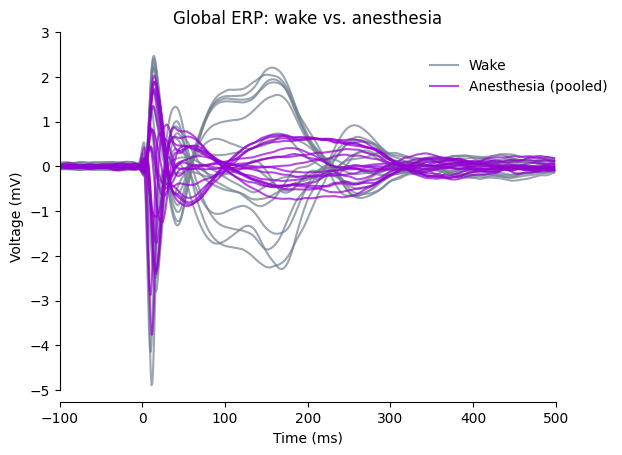

In [109]:
pipeline = 1

all_wake_erps, all_anes_erps = [], []
for anes_name in anes_keys:
    erp_data = erp_datasets[anes_name]
    anes_cond = infr.get_anes_cond_label(erp_data)
    all_wake_erps.append(erp_data.sel(condition='wake').mean(dim='subject').dropna('region').to_numpy())
    all_anes_erps.append(erp_data.sel(condition=anes_cond).mean(dim='subject').dropna('region').to_numpy())

global_wake_p1 = np.mean(np.stack(all_wake_erps), axis=0)
global_anes_p1 = np.mean(np.stack(all_anes_erps), axis=0)

fig, ax = plt.subplots()
ax.plot(time_vec, global_wake_p1, c=plotting.ANES_COLORS['wake'], alpha=0.7, lw=1.5, label='Wake')
ax.plot(time_vec, global_anes_p1, c='darkviolet', alpha=0.7, lw=1.5, label='Anesthesia (pooled)')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(-100, 500), yticks=[-5, -4, -3, -2, -1, 0, 1, 2, 3])
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (mV)')
ax.set_title('Global ERP: wake vs. anesthesia')
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 0.85))
plt.show()

Now we compute the 2 gain matrices, perform the 16 channel simulations (once for each gain matrix). 

Then we calculate its PCIst values and add a hotspot encoding to it, dependeping on which gain matrix was used (wake vs. anasthesia).

In [133]:
gains_p1 = infr.compute_shared_gain(erp_datasets, anes_keys=anes_keys, pipeline=pipeline, num_components=num_components,
                                     weight_by_variance=weight_by_variance_gain)

theta_arr_p1, feature_array_p1 = infr.make_sbi_dataset(
    sim_array.to_numpy(), theta, gains_p1, time_vec, pci_pars, pipeline,
    forward_chunks=forward_chunks, pci_chunks=pci_chunks)

raw_pci_p1 = feature_array_p1[:, 0].numpy()
print(theta_arr_p1.shape, feature_array_p1.shape)  # expect (num_sim*2, num_params), (num_sim*2, 2)
print(f'raw simulated PCIst range (pipeline 1, pre rescale): {raw_pci_p1.min():.1f} to {raw_pci_p1.max():.1f}')
print(f'empirical PCIst range (pooled):                      {emp_all.min():.1f} to {emp_all.max():.1f}')

Pipeline 1:   0%|          | 0/2 [00:00<?, ?it/s]

torch.Size([2000, 4]) torch.Size([2000, 2])
raw simulated PCIst range (pipeline 1, pre rescale): 11.7 to 63.1
empirical PCIst range (pooled):                      28.8 to 112.8


Now we rescale the simulated PCIst values using one shared `(a_p1, b_p1)` pair for the wake and anesthesia simulations combined (not two separate ones), so the wake vs anesthesia comparison right below stays meaningful, on a shared scale rather than two independently rescaled ones.

In [134]:
# own rescale for pipeline 1, fit against the combined wake + anesthesia raw PCIst above
#pcist_rescale_margin_low_p1 = 0.05
#pcist_rescale_margin_high_p1 = 1
# a_p1, b_p1 = infr.fit_pcist_rescale(raw_pci_p1, emp_all, margin_lo=pcist_rescale_margin_low_p1, margin_hi=pcist_rescale_margin_high_p1)

# The a and b values were found previously using the above method.
a_p1, b_p1 = 1.7, 7
print(f'pipeline 1 rescale: PCIst_rescaled = {a_p1:.2f} * PCIst + {b_p1:.2f}')

feature_array_p1[:, 0] = infr.apply_pcist_rescale(feature_array_p1[:, 0], a_p1, b_p1)
rescaled_pci_p1 = feature_array_p1[:, 0].numpy()
print(f'rescaled simulated PCIst range: {rescaled_pci_p1.min():.1f} to {rescaled_pci_p1.max():.1f}')

pipeline 1 rescale: PCIst_rescaled = 1.70 * PCIst + 7.00
rescaled simulated PCIst range: 26.9 to 114.2


A quick check before training anything: does the PCIst value coming out of
the two gain matrices actually differ between wake and anesthesia
simulations?

In [135]:
x_np_p1 = feature_array_p1.numpy()
wake_pci_p1 = x_np_p1[x_np_p1[:, 1] == 0][:, 0]
anes_pci_p1 = x_np_p1[x_np_p1[:, 1] == 1][:, 0]

print('wake PCI mean/std:', wake_pci_p1.mean(), wake_pci_p1.std())
print('anesthesia PCI mean/std:', anes_pci_p1.mean(), anes_pci_p1.std())
print('max |wake - anesthesia| difference:', np.max(np.abs(wake_pci_p1 - anes_pci_p1)))

wake PCI mean/std: 53.69625 19.155157
anesthesia PCI mean/std: 68.386604 22.456669
max |wake - anesthesia| difference: 31.658234


It does! This is interesting.

Now we can plot PCIst distributions in case of Pipeline 1:

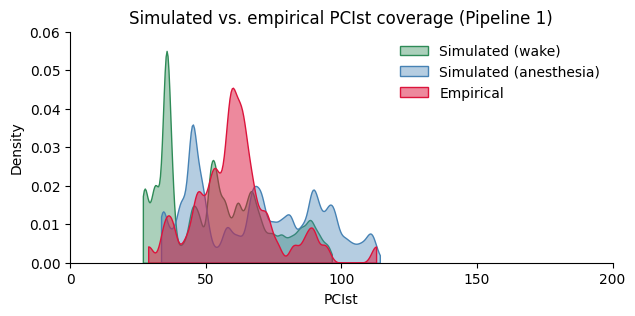

In [136]:
fig, ax = plt.subplots(figsize=(7, 3))
sns.kdeplot(wake_pci_p1, ax=ax, fill=True, color='seagreen', alpha=0.4, label='Simulated (wake)', cut=0, bw_adjust=0.25)
sns.kdeplot(anes_pci_p1, ax=ax, fill=True, color='steelblue', alpha=0.4, label='Simulated (anesthesia)', cut=0, bw_adjust=0.25)
sns.kdeplot(emp_all, ax=ax, fill=True, color='crimson', alpha=0.5, label='Empirical', cut=0, bw_adjust=0.25)
ax.set_xlabel('PCIst')
ax.set_ylabel('Density')
ax.set_title('Simulated vs. empirical PCIst coverage (Pipeline 1)')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 200))
plotting.dedupe_legend(ax, frameon=False)
plt.show()

The simulations projected via the anasthesia gain matrix have in general higher PCIst values than the simulations projected via the wake gain matrix.

This might sound contratuitive, but I came up with a hypothesis (not sure if correct tho):

"Simulated (wake)" and "Simulated (anesthesia)" here are the exact same simulated dynamics, just projected through two different gain matrices, so any difference between the curves reflects the geometry of those matrices, not the underlying complexity of the simulations. The anesthesia matrix pools three drugs (ketamine, propofol, sevoflurane), which likely gives it a spatially busier pattern with more independent components clearing PCIst's SNR gate than the more homogeneous wake matrix, and that alone can push its PCIst values up regardless of the input signal.

In [138]:
x_features_p1 = feature_array_p1.numpy()
if normalize_features:
    scaler_p1 = preprocessing.MinMaxScaler()
    x_features_p1[:, 0:1] = scaler_p1.fit_transform(x_features_p1[:, 0:1])
x_features_p1 = torch.as_tensor(x_features_p1.astype(np.float32))
theta_tensor_p1 = torch.as_tensor(theta_arr_p1)

print('possible encodings, second column:', np.unique(x_features_p1[:, 1].numpy()))

possible encodings, second column: [0. 1.]


It looks like the encodings work. Now we can plot the simulated PCist values vs. the parameters, both for the wake gain matrix and the anesthesia gain matrix. This time we will use circles to show density.

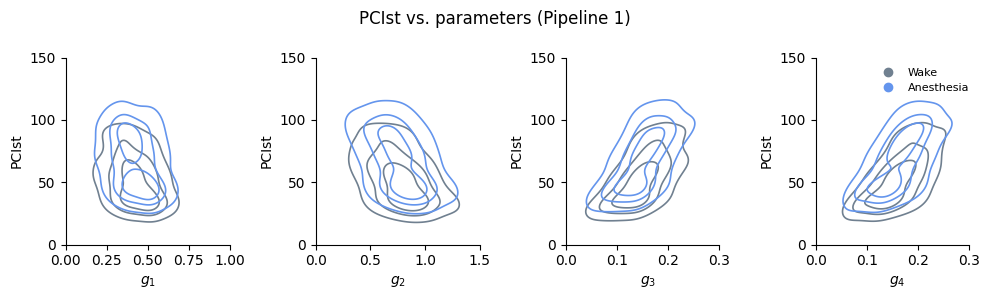

In [249]:
# manually set (lo, hi) and tick list per parameter.
xlims_p1 = [(0, 1), (0, 1.5), (0, 0.32), (0, 0.32)]
xticks_p1 = [(0, 0.25, 0.5, 0.75, 1), (0, 0.5, 1.0, 1.5), (0, 0.1, 0.2, 0.3), (0, 0.1, 0.2, 0.3)]

pci_values_p1 = x_features_p1[:, 0]
plotting.plot_pci_vs_params(
    theta_arr_p1, pci_values_p1, prm_names, param_labels,
    title='PCIst vs. parameters (Pipeline 1)',
    pipeline=1, encoding=x_features_p1[:, 1:2], mode='density',
    xlim=xlims_p0,                    
    xticks=xticks_p0,                
    yticks=[0, 50, 100, 150],
    ylim=(0, 150))   
plt.show()

We see that (like we saw from the distribution plots) the simulated wake PCIst values usually are lower than the simulated anesthesia PCIst values.

And analogous to Pipeline 1, we again see the following correlations:

- `g_1`: Extremely weak negative correlation
- `g_2`: Weak negative correlation
- `g_3`: Positive correlation
- `g_4`: Positive correlation


Now we can train the neural network.

In [140]:
inference_nn_p1 = sbi.inference.SNPE(prior, density_estimator=estimator_type, device=device)
posterior_estimator_p1 = inference_nn_p1.append_simulations(theta_tensor_p1, x_features_p1).train()
posterior_p1 = sbi.inference.DirectPosterior(posterior_estimator_p1, prior)

 Neural network successfully converged after 301 epochs.

For each anesthesia dataset, we feed the real empirical PCIst values (which we gave the hotspot encoding via `infr.build_empirical_features` ->
`encode_condition`) into the trained Pipeline 1 posterior. 

Then we draw num_samples posterior samples of the g-parameters per condition (wake vs. anesthesia), after which we pool everything into one dataframe (theta_df_p1) for plotting.

In [141]:
all_posteriors_p1 = {}

for anes_name in anes_keys:
    emp_features = emp_feature_dict[anes_name]
    emp_array = infr.build_empirical_features(emp_features, pipeline)
    if normalize_features:
        # scaler_p1, not global_emp_max, see the note on this fix in Pipeline 0 above
        emp_array[:, 0:1] = scaler_p1.transform(emp_array[:, 0:1])

    emp_tensor = torch.tensor(emp_array, dtype=torch.float32)
    theta_samples = posterior_p1.sample_batched(sample_shape=(num_samples,), x=emp_tensor, show_progress_bars=False)

    n_subjects = emp_features.sizes['subject']
    n_conditions = emp_features.sizes['condition']
    theta_samples = theta_samples.permute(1, 0, 2).reshape(n_conditions, n_subjects, num_samples, num_params).permute(1, 0, 3, 2)

    all_posteriors_p1[anes_name] = xr.DataArray(
        theta_samples.numpy(), dims=posterior_dims,
        coords=dict(subject=emp_features.subject, condition=emp_features.condition, theta=prm_names))

if normalize_posteriors:
    stacked_p1 = xr.concat(list(all_posteriors_p1.values()), dim='anes')
    global_param_max_p1 = stacked_p1.max(('anes', 'subject', 'condition', 'sample'))
    for anes_name in anes_keys:
        all_posteriors_p1[anes_name] = all_posteriors_p1[anes_name] / global_param_max_p1

for anes_name in anes_keys:
    out_dir = f'output/{pipeline}_{num_sim}/{anes_name}'
    os.makedirs(out_dir, exist_ok=True)
    all_posteriors_p1[anes_name].to_netcdf(out_dir + f'/theta_posteriors_{pipeline}_{anes_name}.nc')

theta_df_p1 = infr.pool_posteriors(all_posteriors_p1)


We perform a direct check of whether the state flag actually changes anything: two identical PCIst values (`pcist`), one tagged wake and one tagged anesthesia, fed straight into the posterior.

In [257]:
pcist_test = 60
with torch.no_grad():
    x_wake = torch.tensor([[pcist_test, 0.0]])
    x_anes = torch.tensor([[pcist_test, 1.0]])
    s_wake = posterior_p1.sample((5000,), x=x_wake, show_progress_bars=False)
    s_anes = posterior_p1.sample((5000,), x=x_anes, show_progress_bars=False)


print(f' posterior mean shift (anesthesia - wake), same PCIst value: {pcist_test}')
for i, prm in enumerate(prm_names):
    shift = (s_anes.mean(0) - s_wake.mean(0))[i].item()
    pct_shift = shift / jrm.DEFAULT_PARAMS_TEMPORAL[prm] * 100
    effect_size = shift / prior_stds[prm]
    print(f'  {prm}: {shift:.4f}  ({pct_shift:+.1f}% of default, {effect_size:+.2f} prior SD)')

 posterior mean shift (anesthesia - wake), same PCIst value: 60
  g_1: 0.0281  (+6.7% of default, +0.22 prior SD)
  g_2: 0.0853  (+11.2% of default, +0.37 prior SD)
  g_3: -0.0124  (-8.3% of default, -0.28 prior SD)
  g_4: -0.0211  (-13.2% of default, -0.44 prior SD)


These shifts look small, but are not negligible.

We see that for a given PCIst value the `g_3` and `g_4` parameters are estimated to be higher if this is coming from wake data than if this is coming from anesthesia data. And the opposite holds for `g_1` and `g_2`.

We already saw this in the above PCIst vs. parameter plot.

Now we can plot the full posteriors for Pipeline 1.

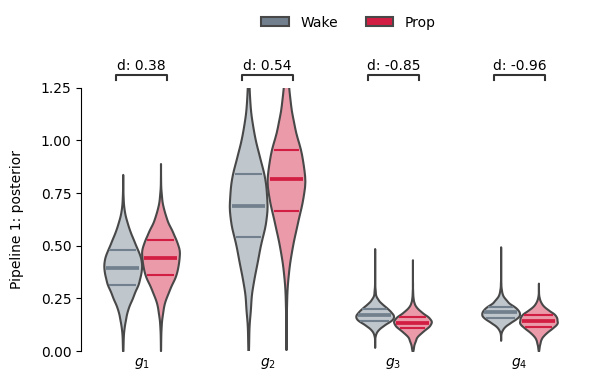

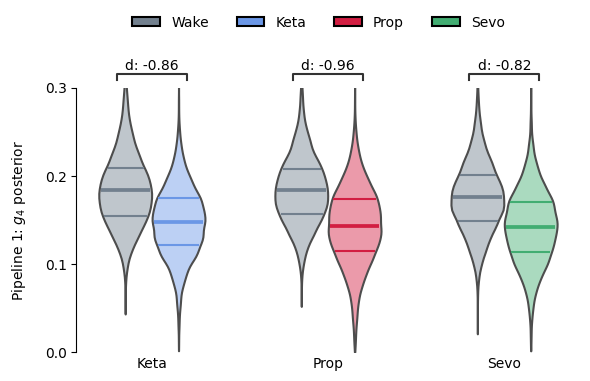

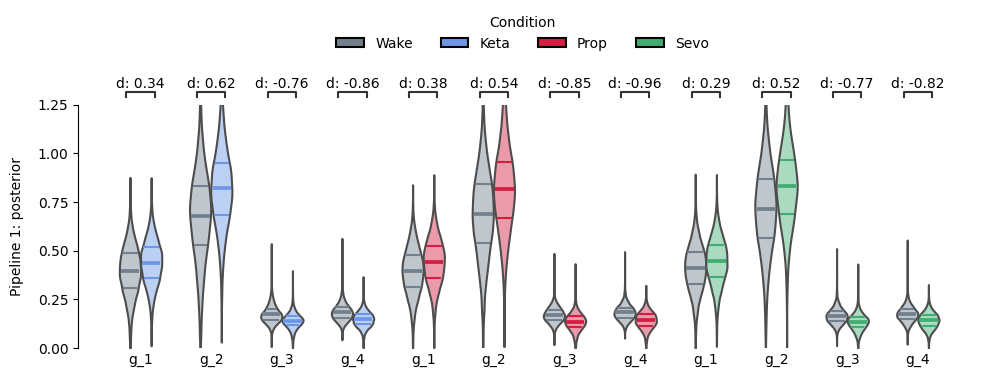

In [258]:
dataset_to_plot = 'prop'
sel_param = 'g_4'

fig1, ax1 = plt.subplots(figsize=(6, 4))
plotting.plot_single_dataset_comparison(fig1, ax1, theta_df_p1, dataset_to_plot, plotting.DATASET_PALETTES[dataset_to_plot],
                                         lw=1.5, legend=True, saturation=0.9, custom_labels=list(param_labels.values()),
                                         ylabel='Pipeline 1: posterior', width=0.6, labelpad=12, lgd_loc=(0.35, 1.2),
                                         theta_column='theta_label',
                                         y_lim=(0, 1.25), y_ticks=(0, 0.25, 0.50, 0.75, 1.0, 1.25))

fig2, ax2 = plt.subplots(figsize=(6, 4))
plotting.plot_parameter_across_datasets(fig2, ax2, theta_df_p1, sel_param, anes_keys, plotting.DATASET_PALETTES,
                                         lw=1.5, legend=True, saturation=0.9,
                                         ylabel=f'Pipeline 1: {param_labels[sel_param]} posterior',
                                         width=0.6, labelpad=12, lgd_loc=(0.1, 1.2), theta_column='theta_label',
                                         y_lim=(0, 0.3), y_ticks=(0, 0.1, 0.2, 0.3))

fig3, ax3 = plt.subplots(figsize=(10, 4))
plotting.plot_pooled_posteriors(fig3, ax3, theta_df_p1, anes_keys, plotting.DATASET_PALETTES, lw=1.5, legend=True,
                                 saturation=0.9, ylabel='Pipeline 1: posterior', width=0.6, lgd_loc=(0.28, 1.2),
                                 theta_column='theta_label',
                                 y_lim=(0, 1.25), y_ticks=(0, 0.25, 0.50, 0.75, 1.0, 1.25))

plt.show()

If we compare this to the results from Pipeline 0, we see that the Cohen's d values are always more than twice as big as before.

### Unit-norm gain matrix invariance

Now we will show that with unit-norm gain matrices, the simulated (theta, PCIst) training pairs are exactly identical for wake and anesthesia. 

As a solution we set in this notebook `weight_by_variance_gain = True`, so the flag isn't guaranteed to be uninformative in the first place, see below for what that changes.

First we construct two gain matrices via the default way (`weight_by_variance=False`), from the pooled wake and pooled anesthesia averages. Forward-project the same single-channel trace through both and compare PCIst.

Then we do the same with the gain matrices this notebook actually uses (`gains_p1`, built with `weight_by_variance_gain = True`).

Then we can compare the PCIst values gotten from both methods.

In [144]:
demo_pci_pars = dict(pci_pars, n_steps=20)

with jax.default_device(infr.cpu_device):
    example_sim = jax.device_put(sim_array.isel(simulation=0).to_numpy(), infr.cpu_device)
    time_vec_cpu = jax.device_put(np.asarray(time_vec), infr.cpu_device)

    # baseline case: unit norm gain matrices
    G_wake_unit, _ = infr.compute_gain_matrix_jax(global_wake_p1, n_comp=num_components, weight_by_variance=False)
    G_anes_unit, _ = infr.compute_gain_matrix_jax(global_anes_p1, n_comp=num_components, weight_by_variance=False)
    G_wake_unit_cpu = jax.device_put(np.asarray(G_wake_unit), infr.cpu_device)
    G_anes_unit_cpu = jax.device_put(np.asarray(G_anes_unit), infr.cpu_device)

    Y_via_wake_unit = infr.compute_forward_solution_multimode_jax(example_sim, G_wake_unit_cpu)
    Y_via_anes_unit = infr.compute_forward_solution_multimode_jax(example_sim, G_anes_unit_cpu)
    pci_via_wake_unit = pcist.compute_pci(Y_via_wake_unit, time_vec_cpu, n_components=Y_via_wake_unit.shape[0], **demo_pci_pars)
    pci_via_anes_unit = pcist.compute_pci(Y_via_anes_unit, time_vec_cpu, n_components=Y_via_anes_unit.shape[0], **demo_pci_pars)

    # what this notebook actually uses: gains_p1, built with weight_by_variance_gain = True
    G_wake_cpu = jax.device_put(np.asarray(gains_p1['wake']), infr.cpu_device)
    G_anes_cpu = jax.device_put(np.asarray(gains_p1['anes']), infr.cpu_device)
    Y_via_wake = infr.compute_forward_solution_multimode_jax(example_sim, G_wake_cpu)
    Y_via_anes = infr.compute_forward_solution_multimode_jax(example_sim, G_anes_cpu)
    pci_via_wake = pcist.compute_pci(Y_via_wake, time_vec_cpu, n_components=Y_via_wake.shape[0], **demo_pci_pars)
    pci_via_anes = pcist.compute_pci(Y_via_anes, time_vec_cpu, n_components=Y_via_anes.shape[0], **demo_pci_pars)

print('weight_by_variance=False (unit norm), same simulation:')
print('  PCIst via G_wake:', float(pci_via_wake_unit), ' via G_anes:', float(pci_via_anes_unit),
      ' diff:', float(pci_via_wake_unit) - float(pci_via_anes_unit))
print()
print(f'weight_by_variance={weight_by_variance_gain} (what this notebook actually uses), same simulation:')
print('  PCIst via G_wake:', float(pci_via_wake), ' via G_anes:', float(pci_via_anes),
      ' diff:', float(pci_via_wake) - float(pci_via_anes))

weight_by_variance=False (unit norm), same simulation:
  PCIst via G_wake: 46.188751220703125  via G_anes: 46.188751220703125  diff: 0.0

weight_by_variance=True (what this notebook actually uses), same simulation:
  PCIst via G_wake: 11.602409362792969  via G_anes: 15.457831382751465  diff: -3.855422019958496


The first difference above comes out at exactly 0 for literally any pair of gain matrices built with `weight_by_variance=False`. 


Here's why:

With `weight_by_variance=False`, `compute_gain_matrix_jax` always returns the top right singular vectors of whatever data it's given, each already unit
norm and orthohonal from the SVD. So every gain matrix `G` it can produce this way has orthonormal columns: $G^\top G = I$. 

The forward-projected signal is $Y = X G^\top$, where $X$ is the (fixed, gain matrix independent) delay-embedded single-channel simulation. So $Y^\top Y = G (X^\top X) G^\top$. And because $G^\top G = I$, $Y$'s nonzero eigenvalues, and its eigenvectors expressed back in $X$'s own coordinate space, don't depend on $G$ at all. 

`compute_pci` derives an SVD basis from $Y$ (`reduce_dimensions`/`get_svd`) and everything downstream (`quantify_transitions`, all Euclidean distance based) runs in that recovered basis. So with unit-norm gain matrices, PCIst is a function of the single-channel simulation alone, never of which gain matrix carried it into sensor space.


That's exactly why this notebook sets `weight_by_variance_gain = True`. Meaning that each column get scaled by its singular value share ($S / \sum S$). This breaks $G^\top G = I$, so the argument above no longer applies.

The second difference number printed above confirms it, PCIst now genuinely differs depending on which gain matrix was used. 

This is a partial fix, not a full one. Every channel is still a deterministic delayed copy of the same single source, weighting just changes how much each delayed copy  contributes. A more complete fix would be simulating several coupled Jansen-Rit sources instead of one, giving the forward-projected signal real spatial structure to begin with.

Conclusion: The condition encoding columns can carry real information about theta during training (if `weight_by_variance_gain=True`).

## Pipeline 2: per-condition gain matrices

Four gain matrices this time, one for the pooled wake average and one per anesthetic (keta, prop, sevo separately instead of pooled). The encoding
becomes a 4-way one-hot: `[1,0,0,0]` for wake, `[0,1,0,0]` for keta, and so on (`infr.encode_condition` with `pipeline >= 2` handles this, see
`inference_utils.py`).

In [156]:
pipeline = 2

gains_p2 = infr.compute_shared_gain(erp_datasets, anes_keys=anes_keys, pipeline=pipeline, num_components=num_components,
                                     weight_by_variance=weight_by_variance_gain)

theta_arr_p2, feature_array_p2 = infr.make_sbi_dataset(
    sim_array.to_numpy(), theta, gains_p2, time_vec, pci_pars, pipeline,
    forward_chunks=forward_chunks, pci_chunks=pci_chunks)

raw_pci_p2 = feature_array_p2[:, 0].numpy()
print(theta_arr_p2.shape, feature_array_p2.shape)  # expect (num_sim*4, num_params), (num_sim*4, 5)
print(f'raw simulated PCIst range (pipeline 2, pre rescale): {raw_pci_p2.min():.1f} to {raw_pci_p2.max():.1f}')
print(f'empirical PCIst range (pooled):                      {emp_all.min():.1f} to {emp_all.max():.1f}')

Pipeline 2:   0%|          | 0/4 [00:00<?, ?it/s]

torch.Size([4000, 4]) torch.Size([4000, 5])
raw simulated PCIst range (pipeline 2, pre rescale): 11.7 to 69.4
empirical PCIst range (pooled):                      28.8 to 112.8


Pipeline 2 has four gain matrices, one per condition (wake, keta, prop, sevo), each built from its own condition specific ERP average. That is yet another set of raw PCIst values, on its own scale again, different from both Pipeline 0's and Pipeline 1's. So this pipeline fits its own rescale too, one shared `(a_p2, b_p2)` pair fit against all four conditions' simulated PCIst combined. So that keta/prop/sevo/wake stay on the same scale relative to each other after rescaling.

In [157]:
# pcist_rescale_margin_low_p2 = 0.05
# pcist_rescale_margin_high_p2 = 1
# a_p2, b_p2 = infr.fit_pcist_rescale(raw_pci_p2, emp_all, margin_lo=pcist_rescale_margin_low_p2, margin_hi=pcist_rescale_margin_high_p2)

# a and b were previously found using the above method
a_p2, b_p2 = 1.5, 10
print(f'pipeline 2 rescale: PCIst_rescaled = {a_p2:.2f} * PCIst + {b_p2:.2f}')

rescaled_feature_array_p2 = infr.apply_pcist_rescale(feature_array_p2[:, 0], a_p2, b_p2)
rescaled_pci_p2 = rescaled_feature_array_p2.numpy()
print(f'rescaled simulated PCIst range: {rescaled_pci_p2.min():.1f} to {rescaled_pci_p2.max():.1f}')

pipeline 2 rescale: PCIst_rescaled = 1.50 * PCIst + 10.00
rescaled simulated PCIst range: 27.5 to 114.2


Coverage check, split out by condition this time.

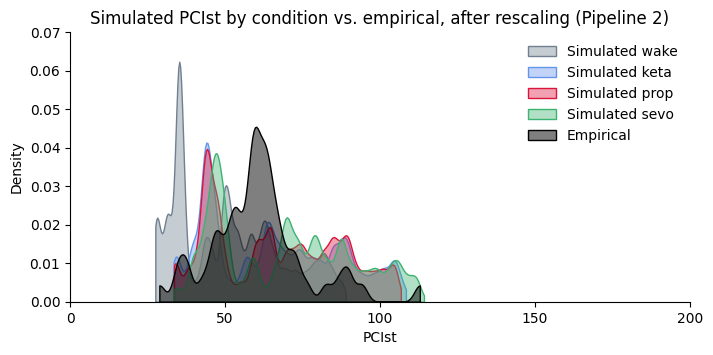

In [158]:
# split the rescaled simulated PCIst by condition, using the one hot columns 1 to 4
conditions_p2 = ['wake', 'keta', 'prop', 'sevo']
cond_index_p2 = feature_array_p2[:, 1:5].numpy().argmax(axis=1)
pci_by_cond_p2 = {cond: rescaled_pci_p2[cond_index_p2 == i] for i, cond in enumerate(conditions_p2)}

series_p2 = {f'Simulated {cond}': pci_by_cond_p2[cond] for cond in conditions_p2}
series_p2['Empirical'] = emp_all

colors_p2 = {f'Simulated {cond}': plotting.ANES_COLORS[cond] for cond in conditions_p2}
colors_p2['Empirical'] = 'k'

fig, ax = plt.subplots(figsize=(8, 3.5))
plotting.plot_pci_kde_comparison(ax, series_p2, colors=colors_p2,
                                  title='Simulated PCIst by condition vs. empirical, after rescaling (Pipeline 2)')
plt.show()

In [159]:
x_features_p2 = feature_array_p2.numpy()
if normalize_features:
    scaler_p2 = preprocessing.MinMaxScaler()
    x_features_p2[:, 0:1] = scaler_p2.fit_transform(x_features_p2[:, 0:1])
x_features_p2 = torch.as_tensor(x_features_p2.astype(np.float32))
theta_tensor_p2 = torch.as_tensor(theta_arr_p2)

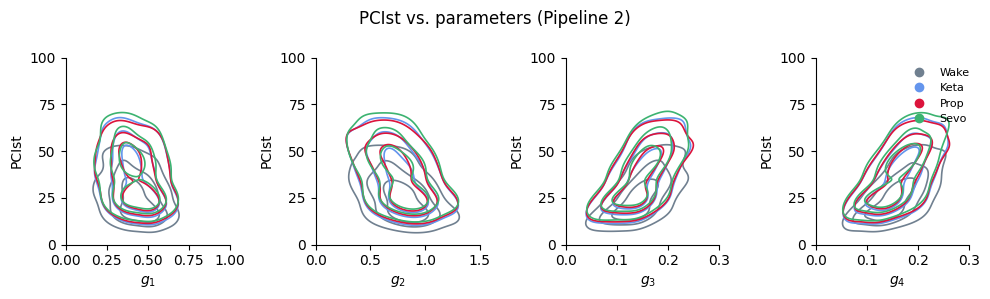

In [262]:
xlims_p2 = [(0, 1), (0, 1.5), (0, 0.32), (0, 0.32)]
xticks_p2 = [(0, 0.25, 0.5, 0.75, 1), (0, 0.5, 1.0, 1.5), (0, 0.1, 0.2, 0.3), (0, 0.1, 0.2, 0.3)]

pci_values_p2 = x_features_p2[:, 0]
plotting.plot_pci_vs_params(
    theta_arr_p2, pci_values_p2, prm_names, param_labels,
    title='PCIst vs. parameters (Pipeline 2)',
    pipeline=2, encoding=x_features_p2[:, 1:5], mode='density',
    xlim=xlims_p0,                    
    xticks=xticks_p0,                 
    yticks=[0, 25, 50, 75, 100],
    ylim=(0, 100))   
plt.show()

In [161]:
inference_nn_p2 = sbi.inference.SNPE(prior, density_estimator=estimator_type, device=device)
posterior_estimator_p2 = inference_nn_p2.append_simulations(theta_tensor_p2, x_features_p2).train()
posterior_p2 = sbi.inference.DirectPosterior(posterior_estimator_p2, prior)

 Neural network successfully converged after 305 epochs.

In [162]:
all_posteriors_p2 = {}

for anes_name in anes_keys:
    emp_features = emp_feature_dict[anes_name]
    emp_array = infr.build_empirical_features(emp_features, pipeline)
    if normalize_features:
        emp_array[:, 0:1] = scaler_p2.transform(emp_array[:, 0:1])

    emp_tensor = torch.tensor(emp_array, dtype=torch.float32)
    theta_samples = posterior_p2.sample_batched(sample_shape=(num_samples,), x=emp_tensor, show_progress_bars=False)

    n_subjects = emp_features.sizes['subject']
    n_conditions = emp_features.sizes['condition']
    theta_samples = theta_samples.permute(1, 0, 2).reshape(n_conditions, n_subjects, num_samples, num_params).permute(1, 0, 3, 2)

    all_posteriors_p2[anes_name] = xr.DataArray(
        theta_samples.numpy(), dims=posterior_dims,
        coords=dict(subject=emp_features.subject, condition=emp_features.condition, theta=prm_names))

if normalize_posteriors:
    stacked_p2 = xr.concat(list(all_posteriors_p2.values()), dim='anes')
    global_param_max_p2 = stacked_p2.max(('anes', 'subject', 'condition', 'sample'))
    for anes_name in anes_keys:
        all_posteriors_p2[anes_name] = all_posteriors_p2[anes_name] / global_param_max_p2

for anes_name in anes_keys:
    out_dir = f'output/{pipeline}_{num_sim}/{anes_name}'
    os.makedirs(out_dir, exist_ok=True)
    all_posteriors_p2[anes_name].to_netcdf(out_dir + f'/theta_posteriors_{pipeline}_{anes_name}.nc')

theta_df_p2 = infr.pool_posteriors(all_posteriors_p2)

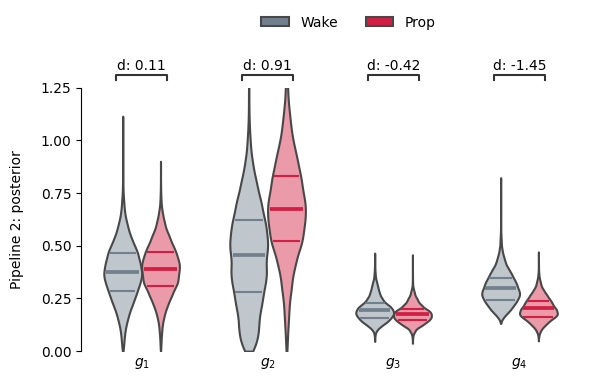

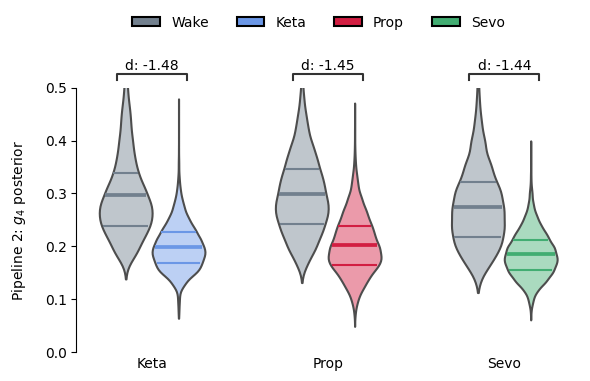

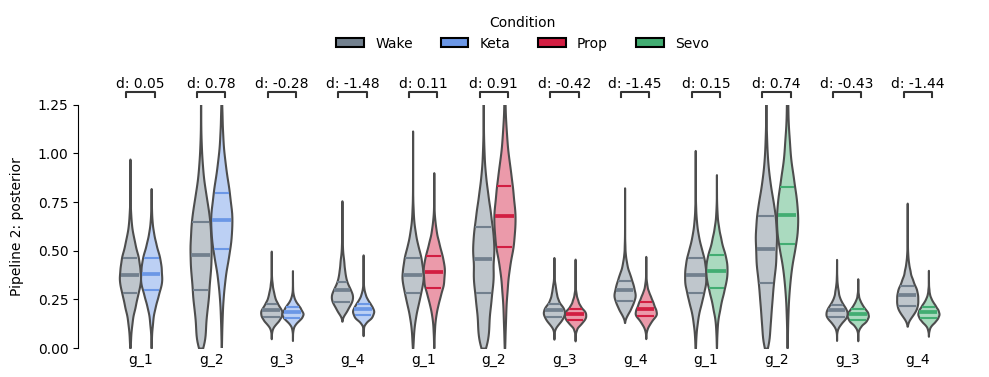

In [265]:
dataset_to_plot = 'prop'
sel_param = 'g_4'

fig1, ax1 = plt.subplots(figsize=(6, 4))
plotting.plot_single_dataset_comparison(fig1, ax1, theta_df_p2, dataset_to_plot, plotting.DATASET_PALETTES[dataset_to_plot],
                                         lw=1.5, legend=True, saturation=0.9, custom_labels=list(param_labels.values()),
                                         ylabel='Pipeline 2: posterior', width=0.6, labelpad=12, lgd_loc=(0.35, 1.2),
                                         y_lim=(0, 1.25), y_ticks=(0, 0.25, 0.50, 0.75, 1.0, 1.25),
                                         theta_column='theta_label')

fig2, ax2 = plt.subplots(figsize=(6, 4))
plotting.plot_parameter_across_datasets(fig2, ax2, theta_df_p2, sel_param, anes_keys, plotting.DATASET_PALETTES,
                                         lw=1.5, legend=True, saturation=0.9,
                                         ylabel=f'Pipeline 2: {param_labels[sel_param]} posterior',
                                         width=0.6, labelpad=12, lgd_loc=(0.1, 1.2), theta_column='theta_label',
                                         y_lim=(0, 0.5), y_ticks=(0, 0.1, 0.2, 0.3, 0.4, 0.5))

fig3, ax3 = plt.subplots(figsize=(10, 4))
plotting.plot_pooled_posteriors(fig3, ax3, theta_df_p2, anes_keys, plotting.DATASET_PALETTES, lw=1.5, legend=True,
                                 saturation=0.9, ylabel='Pipeline 2: posterior', width=0.6, lgd_loc=(0.28, 1.2),
                                 theta_column='theta_label', y_lim=(0, 1.25), y_ticks=(0, 0.25, 0.50, 0.75, 1.0, 1.25))

plt.show()

We see that the d-distance for `g_2` and `g_4` get even bigger compared to P0 and P1, while the d-distance for `g_1` and `g_3` get smaller.

## Comparing results across pipelines

Now we can compare the results from Pipeline 0, 1 and 2 (Pipeline 3 and 4 take too long and are in the appendix) side by side.

In [266]:
pipeline_dfs = {'P0': theta_df_p0, 'P1': theta_df_p1, 'P2': theta_df_p2}
dataset_to_plot = 'prop'
sel_param = 'g_4'

First we compare the results for a specific parameter (in this case `g_4`, because that was the parameter which had the highest d-distance).

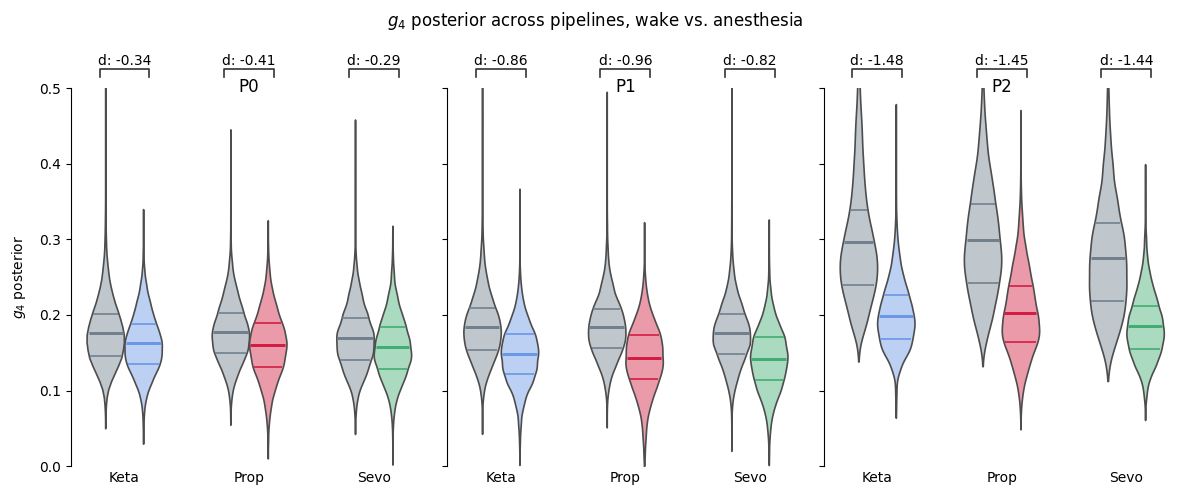

In [269]:
fig, axes = plt.subplots(1, len(pipeline_dfs), figsize=(4 * len(pipeline_dfs), 5), sharey=True)
for i, (ax, (label, df)) in enumerate(zip(axes, pipeline_dfs.items())):
    plotting.plot_parameter_across_datasets(
        fig, ax, df, sel_param, anes_keys, plotting.DATASET_PALETTES, lw=1.2, legend=False,
        saturation=0.9, ylabel=f'{param_labels[sel_param]} posterior' if i == 0 else '',
        width=0.6, labelpad=8, y_ticks=[0, 0.1, 0.2, 0.3, 0.4, 0.5], y_lim=(0, 0.5))
    label_y = 0.98
    ax.text(0.5, label_y, label, transform=ax.transAxes, ha='center', va='bottom',
            fontsize=plt.rcParams['axes.titlesize'])

fig.suptitle(f'{param_labels[sel_param]} posterior across pipelines, wake vs. anesthesia')
fig.tight_layout()
plt.show()

Now, we compare the results for a specific anesthesia (in this case `sevo`, because that was the anesthehsia which had the highest d-distance).

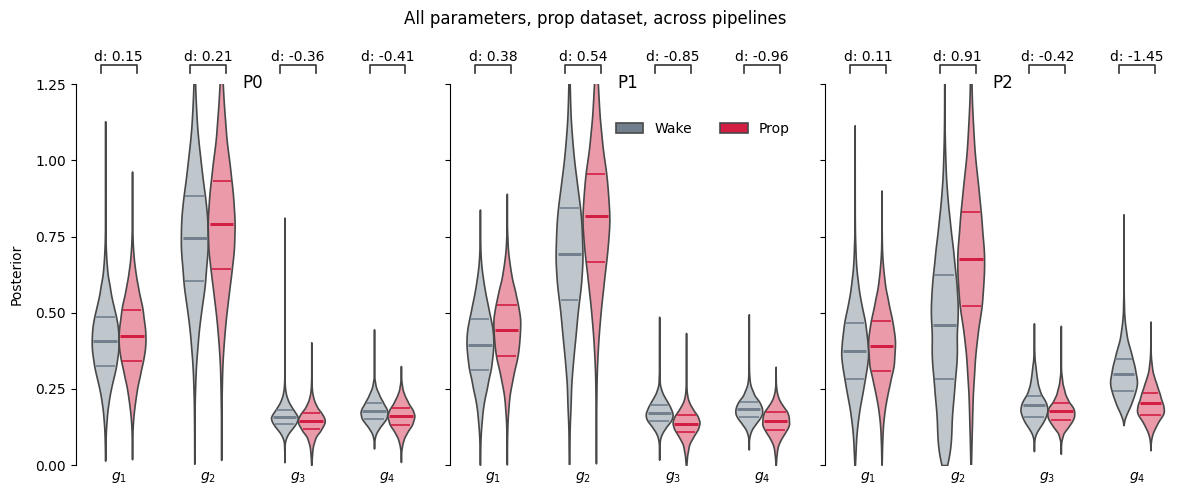

In [271]:
fig, axes = plt.subplots(1, len(pipeline_dfs), figsize=(4 * len(pipeline_dfs), 5), sharey=True)
for i, (ax, (label, df)) in enumerate(zip(axes, pipeline_dfs.items())):
    plotting.plot_single_dataset_comparison(
        fig, ax, df, dataset_to_plot, plotting.DATASET_PALETTES[dataset_to_plot], lw=1.2, legend=(i == 1),
        saturation=0.9, custom_labels=list(param_labels.values()),
        ylabel='Posterior' if i == 0 else '', width=0.6, labelpad=8, lgd_loc=(0.45, 0.85),
        theta_column='theta_label', y_ticks=[0, 0.25, 0.5, 0.75, 1.00, 1.25], y_lim=(0, 1.25))
    label_y = 0.98
    ax.text(0.5, label_y, label, transform=ax.transAxes, ha='center', va='bottom',
            fontsize=plt.rcParams['axes.titlesize'])

fig.suptitle(f'All parameters, {dataset_to_plot} dataset, across pipelines')
fig.tight_layout()
plt.show()

## Comparing gain matrices (P0-P2)

In addition to comparing the posteriors over different pipelines, we can also compare the constructed gain matrices themselves.

On the one hand we can compare them within one pipeline, for example: do the two P1 gain matrices actually differ from each other?

On the other hand we can compare across pipelines (does P0's one shared matrix look anything like P1/P2's).

In [167]:
gain_list_p0, labels_p0 = infr.flatten_gains(gains_p0, pipeline=0)
gain_list_p1, labels_p1 = infr.flatten_gains(gains_p1, pipeline=1)
gain_list_p2, labels_p2 = infr.flatten_gains(gains_p2, pipeline=2)

gain_list_p0, labels_p0 = gain_list_p0[:1], ['p0']

gain_lists = {'P0': gain_list_p0, 'P1': gain_list_p1, 'P2': gain_list_p2}
for label, gl in gain_lists.items():
    print(f'{label}: {len(gl)} gain matrices, shape {gl[0].shape}')

P0: 1 gain matrices, shape (16, 4)
P1: 2 gain matrices, shape (16, 4)
P2: 4 gain matrices, shape (16, 4)


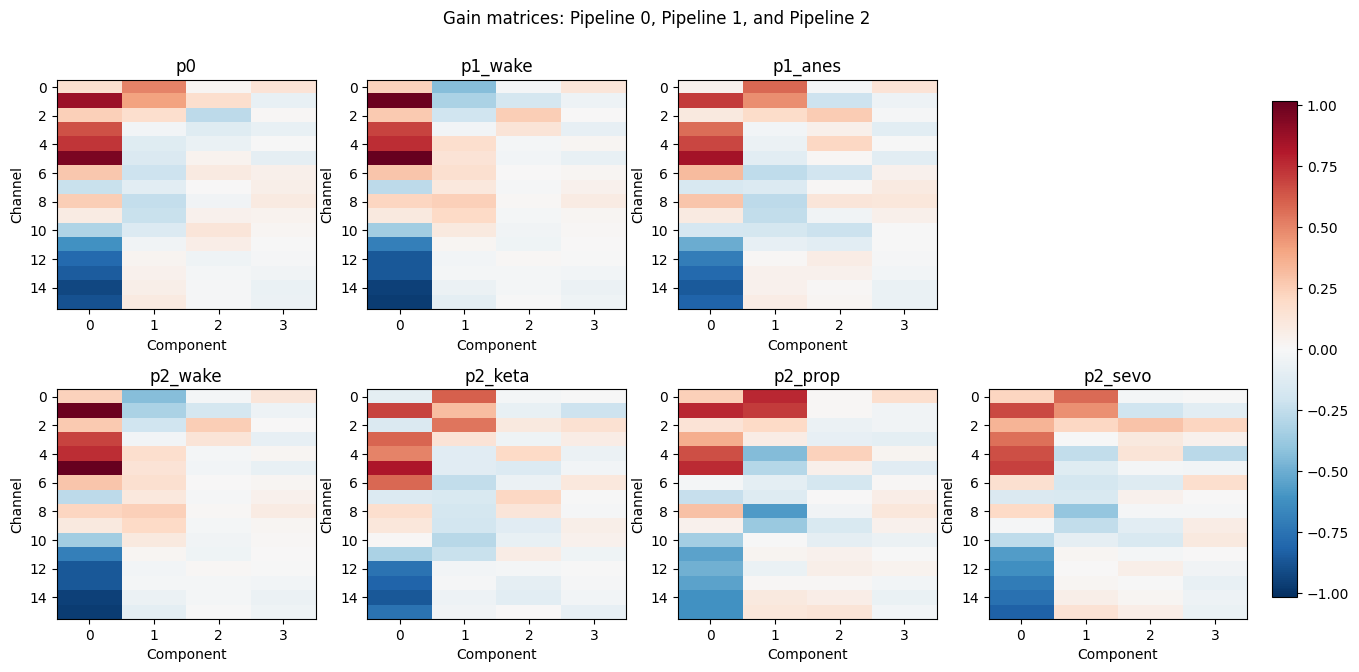

In [168]:
top_row_gains = list(zip(labels_p0 + labels_p1, gain_list_p0 + gain_list_p1))
bottom_row_gains = list(zip(labels_p2, gain_list_p2))

vmax = max(np.abs(np.asarray(G)).max() for _, G in top_row_gains + bottom_row_gains)

n_cols = 4
fig, axes = plt.subplots(2, n_cols, figsize=(4 * n_cols, 7), gridspec_kw={'hspace': 0.35})

for ax, (label, G) in zip(axes[0], top_row_gains):
    G = np.asarray(G)
    im = ax.imshow(G, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
    ax.set_title(label)
    ax.set_xlabel('Component')
    ax.set_ylabel('Channel')
    ax.set_xticks(range(G.shape[1]))
for ax in axes[0][len(top_row_gains):]:
    ax.axis('off')

for ax, (label, G) in zip(axes[1], bottom_row_gains):
    G = np.asarray(G)
    im = ax.imshow(G, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
    ax.set_title(label)
    ax.set_xlabel('Component')
    ax.set_ylabel('Channel')
    ax.set_xticks(range(G.shape[1]))

fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
fig.suptitle('Gain matrices: Pipeline 0, Pipeline 1, and Pipeline 2')
plt.show()

As expected are the gain matrices p1_wake and p2_wake identical (these were constructed from same wake average ERP).

Now we calculate the within pipeline gain matrix simularity.

1.0 means the column spaces coincide, 0 means they are orthogonal, and for two unrelated random gain matrices of this size (16 channels, rank 4) chance
level similarity is around 4/16 = 0.25.

In [169]:
within_means, within_sems, within_npairs = {}, {}, {}

for label, gl in gain_lists.items():
    if len(gl) < 2:
        continue  # P0
    sim_mat = infr.compute_similarity_matrix(gl)
    n = sim_mat.shape[0]
    pairs = sim_mat[np.triu_indices(n, k=1)]
    within_means[label] = pairs.mean()
    within_sems[label] = pairs.std(ddof=1) / np.sqrt(len(pairs))
    within_npairs[label] = len(pairs)

for label in within_means:
    if within_npairs[label] == 1:
        # P1
        print(f'within {label}: similarity = {within_means[label]:.3f}')
    else:
        print(f'within {label}: mean similarity = {within_means[label]:.3f} +/- {within_sems[label]:.3f} (SEM)')

within P1: similarity = 0.837
within P2: mean similarity = 0.715 +/- 0.022 (SEM)


Now the pairwise similarity between every pair of pipelines, both the
average pipeline-vs-pipeline number and the full matrix-by-matrix picture.

within P1: similarity = 0.837
within P2: mean similarity = 0.715 +/- 0.022 (SEM)


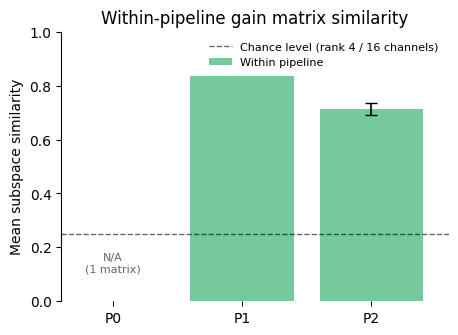

In [195]:
within_means, within_sems, within_npairs = {}, {}, {}
for label, gl in gain_lists.items():
    if len(gl) < 2:
        continue  # P0
    sim_mat = infr.compute_similarity_matrix(gl)
    n = sim_mat.shape[0]
    pairs = sim_mat[np.triu_indices(n, k=1)]
    within_means[label] = pairs.mean()
    within_sems[label] = pairs.std(ddof=1) / np.sqrt(len(pairs))
    within_npairs[label] = len(pairs)

for label in within_means:
    if within_npairs[label] == 1:
        # P1
        print(f'within {label}: similarity = {within_means[label]:.3f}')
    else:
        print(f'within {label}: mean similarity = {within_means[label]:.3f} +/- {within_sems[label]:.3f} (SEM)')

pipeline_labels = list(gain_lists.keys())
n_pipelines = len(pipeline_labels)
pipeline_sim_mat = np.full((n_pipelines, n_pipelines), np.nan)
pipeline_sem_mat = np.full((n_pipelines, n_pipelines), np.nan)  # only meaningful on the diagonal

for i, label_i in enumerate(pipeline_labels):
    for j, label_j in enumerate(pipeline_labels):
        if i == j:
            # reuse within_means/within_sems computed above rather than redoing the pairwise
            # similarity + triu extraction a second time, label_i missing here means P0
            if label_i not in within_means:
                continue
            mean_sim = within_means[label_i]
            pipeline_sem_mat[i, j] = within_sems.get(label_i, np.nan)  # nan for P1, has 1 pair only
        else:
            cross_mat = infr.compute_cross_pipeline_similarity(gain_lists[label_i], gain_lists[label_j])
            mean_sim, _ = infr.summarize_cross_similarity(cross_mat)
        pipeline_sim_mat[i, j] = mean_sim

fig, ax = plt.subplots(figsize=(5, 3.5))
diag_vals = np.array([pipeline_sim_mat[i, i] for i in range(n_pipelines)])
diag_sems = np.array([pipeline_sem_mat[i, i] for i in range(n_pipelines)])
has_value = ~np.isnan(diag_vals)
has_sem = ~np.isnan(diag_sems)
ax.bar(np.arange(n_pipelines)[has_value], diag_vals[has_value], width=0.8, alpha=0.7, color='mediumseagreen', label='Within pipeline')
ax.errorbar(np.arange(n_pipelines)[has_sem], diag_vals[has_sem], yerr=diag_sems[has_sem],
            fmt='none', ecolor='black', capsize=4, lw=1.2)
na_text_xy = {'P0': (0, 0.1)}
for label, (x, y) in na_text_xy.items():
    ax.text(x, y, 'N/A\n(1 matrix)', ha='center', va='bottom', fontsize=8, color='0.4')
ax.set_xlim(-0.4, n_pipelines - 0.4)
ax.set_xticks(range(n_pipelines))
ax.set_xticklabels(pipeline_labels)
ax.set_ylabel('Mean subspace similarity')
ax.set_ylim(0, 1)
ax.set_title('Within-pipeline gain matrix similarity')
ax.axhline(4/16, color='k', ls='--', lw=1, alpha=0.6, label='Chance level (rank 4 / 16 channels)')
ax.legend(frameon=False, fontsize=8)
plotting.modify_axis_spines(ax, which=['y'])
plt.show()

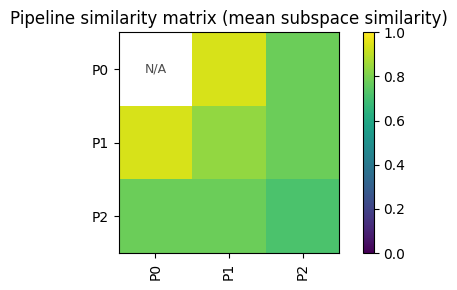

In [172]:
fig, ax = plt.subplots(figsize=(3, 3))
plotting.plot_similarity_matrix(fig, ax, pipeline_sim_mat, pipeline_labels, title='Pipeline similarity matrix (mean subspace similarity)')

for i, label in enumerate(pipeline_labels):
    if np.isnan(pipeline_sim_mat[i, i]):
        ax.text(i, i, 'N/A', ha='center', va='center', fontsize=9, color='0.3')

plt.show()

All values sit in a narrow, high range (roughly 0.75 to 1.0), far above the chance level (4/16 = 0.25) drawn on the bar chart earlier. So the gain matrices across P0, P1, and P2 aren't orthogonal, they largely share the same subspace no matter how the conditions get pooled or split.

P0-P1 is the brightest cell: P0's single grand-average matrix sits almost exactly between P1's two pooled (wake, anesthesia) matrices, so it's barely distinguishable from either. 

P2's own diagonal is the lowest value in the whole matrix, more genuine spread shows up among the four individual anesthetics (wake/keta/prop/sevo) than between wake and anesthesia-in-general.

On the one hand, all values not being equal to 1, tells us that the condition encoding can carry information (which was the point of `weight_by_variance_gain = True`)

But on the other hand, everything seen across pipelines is a subtle perturbation on one dominant shared subspace, not independent spatial signatures.

## Unweighted gain matrix

Every pipeline above uses `weight_by_variance_gain = True`.

But what happens if we repeat Pipeline 0, but this time with `weight_by_variance=False` and with the best `dmax` for unweighted? (We can not reproduce other Pipeline's as they must have different gain matrices, which is not possible if `weight_by_variance=False`).

Do we get the same results?

Again, this section's simulated PCIst gets its own rescale fit against the empirical range.

Here we first set dmax to 420 ms, which we previously found to be the best value for unweigthed.

In [293]:
dmin_unweighted = 0
dmax_unweighted = 420

G_unweighted, _ = infr.compute_gain_matrix_jax(example_avg_erp, n_comp=num_components, weight_by_variance=False)

Y_unweighted = infr.compute_forward_solution_multimode_jax_batch(
    jnp.array(sim_array.to_numpy()), G_unweighted, dmin=dmin_unweighted, dmax=dmax_unweighted, batch_size=forward_chunks)
pci_unweighted = pcist.compute_pci_batch_chunked(
    Y_unweighted, time_vec, batch_size=pci_chunks, full_return=False, n_components=Y_unweighted.shape[1], **pci_pars)
pci_unweighted = np.asarray(pci_unweighted)

# Previously good scaling parameters were found, these are now hardcoded
#pcist_rescale_margin_low = 0.75
# pcist_rescale_margin_high = 3.5
# a_unweighted, b_unweighted = infr.fit_pcist_rescale(pci_unweighted, emp_all, margin_lo=pcist_rescale_margin_low, margin_hi=pcist_rescale_margin_high)

a_unweighted, b_unweighted = 2.3, -42

print(f'unweighted rescale: PCIst_rescaled = {a_unweighted:.1f} * PCIst {b_unweighted:.1f}')

theta_arr_u = np.asarray(theta, dtype=np.float32)
print(theta_arr_u.shape, pci_unweighted.shape)  # expect (num_sim, num_params), (num_sim,), same as Pipeline 0


unweighted rescale: PCIst_rescaled = 2.3 * PCIst -42.0
(1000, 4) (1000,)


In [294]:
x_features_u = pci_unweighted.reshape(-1, 1).astype(np.float32)
x_features_u[:, 0] = infr.apply_pcist_rescale(x_features_u[:, 0], a_unweighted, b_unweighted)

if normalize_features:
    scaler_u = preprocessing.MinMaxScaler()
    x_features_u = scaler_u.fit_transform(x_features_u)

x_features_u = torch.as_tensor(x_features_u.astype(np.float32))
theta_tensor_u = torch.as_tensor(theta_arr_u)

The PCIst vs. `g_i` scatter.

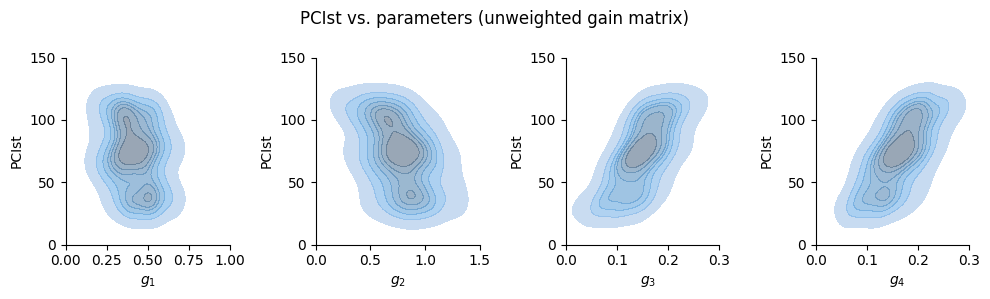

In [295]:
# manually set (lo, hi) and tick list per parameter.
xlims_p0 = [(0, 1), (0, 1.5), (0, 0.32), (0, 0.32)]
xticks_p0 = [(0, 0.25, 0.5, 0.75, 1), (0, 0.5, 1.0, 1.5), (0, 0.1, 0.2, 0.3), (0, 0.1, 0.2, 0.3)]

pci_values_u = x_features_u[:, 0]
plotting.plot_pci_vs_params(
    theta_arr_u, pci_values_u, prm_names, param_labels,
    title='PCIst vs. parameters (unweighted gain matrix)',
    mode='density',
    xlim=xlims_p0,                   
    xticks=xticks_p0,                
    yticks=[0, 50, 100, 150],
    ylim=(0, 150))  
plt.show()

Compared to the other weigthed Pipelines we see approximatly the same correlations between PCIst and the g-parameters (maybe even stronger):

- `g_1`: Extremely weak negative correlation
- `g_2`: Weak negative correlation
- `g_3`: Positive correlation
- `g_4`: Positive correlation

Now it's time for the plot of the PCIst distributiond, to test the overlap.

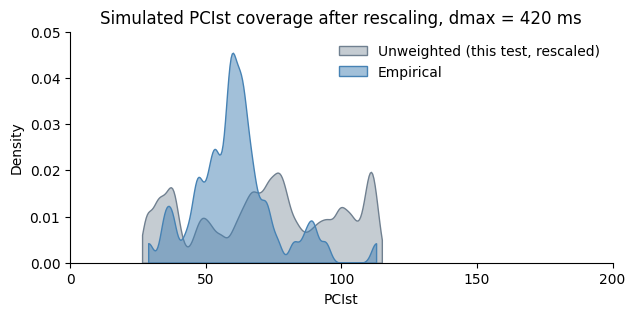

In [296]:
fig, ax = plt.subplots(figsize=(7, 3))
plotting.plot_pci_kde_comparison(ax, {'Unweighted (this test, rescaled)': pci_values_u.numpy(), 'Empirical': emp_all},
                                  title=f'Simulated PCIst coverage after rescaling, dmax = {dmax_unweighted} ms')
plt.show()

Train SNPE the same way as Pipeline 0.

In [297]:
inference_nn_u = sbi.inference.SNPE(prior, density_estimator=estimator_type, device=device)
posterior_estimator_u = inference_nn_u.append_simulations(theta_tensor_u, x_features_u).train()
posterior_u = sbi.inference.DirectPosterior(posterior_estimator_u, prior)

 Neural network successfully converged after 279 epochs.

### Parameter recovery check

Quick parameter recovery check, same idea as Pipeline 0's synthetic validation: we use the same sampled theta (as in P0), and see what the posterior guesses back this time from just its PCIst value.

Sampled g-parameters: tensor([0.5485, 1.0476, 0.1543, 0.1407]) 
Sampled PCIst value: tensor([37.7994])


  0%|          | 0/2000 [00:00<?, ?it/s]

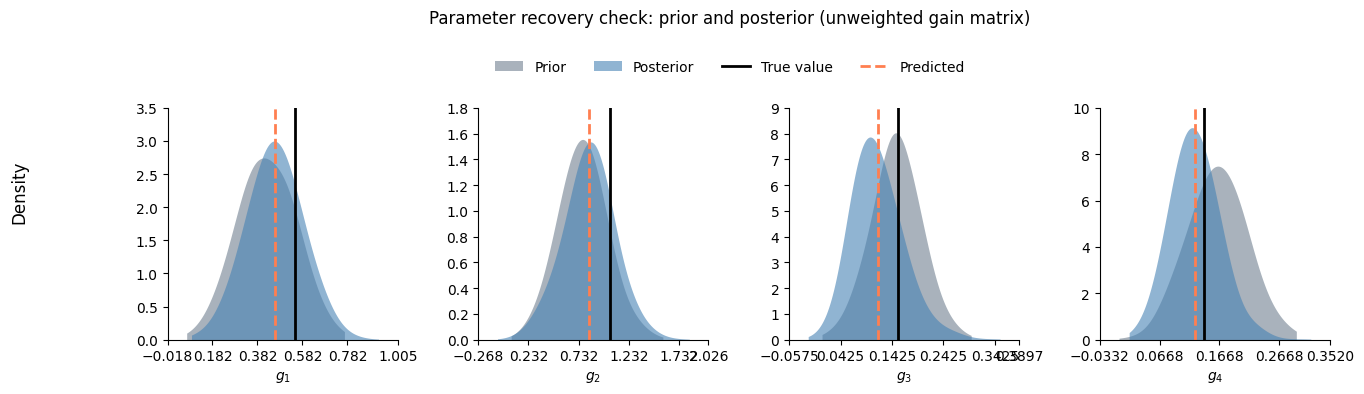

In [298]:
theta_true_ind_u = theta_true_ind
theta_true_sample_u = theta_true_sample
theta_true_feat_u = theta_true_feat
print(f"Sampled g-parameters: {theta_true_sample_u} \nSampled PCIst value: {theta_true_feat_u}")

theta_pred_u = posterior_u.sample((num_samples,), x=theta_true_feat_u).numpy().squeeze()
theta_pred_mean_u = theta_pred_u.mean(0)

fig, axes = plt.subplots(1, num_params, figsize=(15, 3.8))
for i, ax in enumerate(axes):
    sns.kdeplot(theta_tensor_u[:, i].numpy(), ax=ax, fill=True, linewidth=0, color='slategray', alpha=0.6, label='Prior', cut=0, bw_adjust=2)
    sns.kdeplot(theta_pred_u[:, i], ax=ax, fill=True, linewidth=0, color='steelblue', alpha=0.6, label='Posterior', cut=0, bw_adjust=2)
    ax.axvline(theta_true_sample_u.numpy()[i], c='k', ls='-', lw=2, label='True value')
    ax.axvline(theta_pred_mean_u[i], c='coral', ls='--', lw=2, label='Predicted')
    ax.set_xlabel(param_labels[prm_names[i]])
    ax.set_ylabel('')
    lo = min(theta_tensor_u[:, i].numpy().min(), theta_pred_u[:, i].min(), theta_true_sample_u.numpy()[i])
    hi = max(theta_tensor_u[:, i].numpy().max(), theta_pred_u[:, i].max(), theta_true_sample_u.numpy()[i])
    pad = 0.1 * (hi - lo)
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(lo - pad, hi + pad))
handles, labels = axes[0].get_legend_handles_labels()
fig.supylabel('Density', x=0.02)
fig.suptitle('Parameter recovery check: prior and posterior (unweighted gain matrix)', y=0.98)
fig.legend(handles, labels, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 0.88), ncol=4)
fig.subplots_adjust(top=0.72, wspace=0.35)
plt.show()

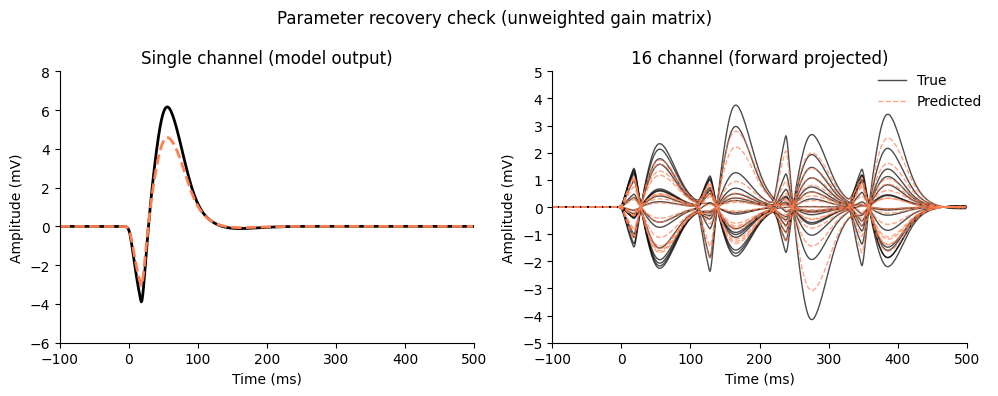

In [299]:
free_params_true_u = dict(zip(prm_names, theta_true_sample_u.numpy()))
free_params_pred_u = dict(zip(prm_names, theta_pred_mean_u))

erp_true_u = jrm.simulate_erp_temporal(ts, input_params, free_params=free_params_true_u, noise_params=(0., 0., 15))
erp_pred_u = jrm.simulate_erp_temporal(ts, input_params, free_params=free_params_pred_u, noise_params=(0., 0., 15))

erp_true_ds_u = np.asarray(erp_true_u)[::ds_sim]
erp_pred_ds_u = np.asarray(erp_pred_u)[::ds_sim]

sensor_true_u = infr.compute_forward_solution_multimode_jax(erp_true_ds_u, G_unweighted).T
sensor_pred_u = infr.compute_forward_solution_multimode_jax(erp_pred_ds_u, G_unweighted).T

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ts[::ds_sim], erp_true_ds_u, lw=2, c='k', label='True')
axes[0].plot(ts[::ds_sim], erp_pred_ds_u, lw=2, ls='--', c='coral', label='Predicted')
axes[0].set_xlabel('Time (ms)')
axes[0].set_ylabel('Amplitude (mV)')
axes[0].set_title('Single channel (model output)')
plotting.modify_axis_spines(axes[0], which=['x', 'y'], xlim=(float(ts.min()), 500))
axes[1].plot(ts[::ds_sim], sensor_true_u, lw=1, alpha=0.7, c='k', label='True')
axes[1].plot(ts[::ds_sim], sensor_pred_u, lw=1, alpha=0.7, ls='--', c='coral', label='Predicted')
axes[1].set_xlabel('Time (ms)')
axes[1].set_ylabel('Amplitude (mV)')
axes[1].set_title('16 channel (forward projected)')
plotting.modify_axis_spines(axes[1], which=['x', 'y'], xlim=(float(ts.min()), 500))
fig.suptitle('Parameter recovery check (unweighted gain matrix)')
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 0.85))
fig.tight_layout()
plt.show()

This again doesn't look great, but the point of this notebook is not to get perfect fits to the original signal, we want to use the PCIst score as a good measure of the signal.

If we compare with P0 results, we see that these unweighted simulations last longer in time.

### Posterior on the empirical data (trial-averaged)

Reusing `emp_feature_dict` from Pipeline 0.

In [300]:
emp_posteriors_u = {}

for anes_name in anes_keys:
    emp_array = emp_feature_dict[anes_name].values.astype(np.float32).reshape(-1, 1)
    if normalize_features:
        emp_array = scaler_u.transform(emp_array)

    emp_tensor = torch.tensor(emp_array, dtype=torch.float32)
    theta_samples = posterior_u.sample_batched(sample_shape=(num_samples,), x=emp_tensor, show_progress_bars=False)

    n_subjects = emp_feature_dict[anes_name].sizes['subject']
    n_conditions = emp_feature_dict[anes_name].sizes['condition']
    theta_samples = theta_samples.permute(1, 2, 0).reshape(n_subjects, n_conditions, num_params, num_samples)

    emp_posteriors_u[anes_name] = xr.DataArray(
        theta_samples.numpy(), dims=posterior_dims,
        coords=dict(subject=emp_feature_dict[anes_name].subject, condition=emp_feature_dict[anes_name].condition, theta=prm_names))

    print(f'{anes_name}: posterior shape {emp_posteriors_u[anes_name].shape}')

for anes_name in anes_keys:
    out_dir = f'output/unweighted_test_{num_sim}/{anes_name}'
    os.makedirs(out_dir, exist_ok=True)
    emp_posteriors_u[anes_name].to_netcdf(out_dir + f'/theta_posteriors_unweighted_{anes_name}.nc')

theta_df_u = infr.pool_posteriors(emp_posteriors_u)

keta: posterior shape (8, 2, 4, 2000)
prop: posterior shape (9, 2, 4, 2000)
sevo: posterior shape (10, 2, 4, 2000)


### Plotting the unweighted test posteriors

Same layout as Pipeline 0's posteriors above.

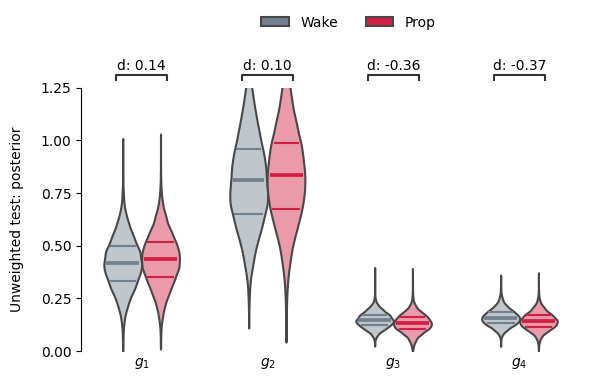

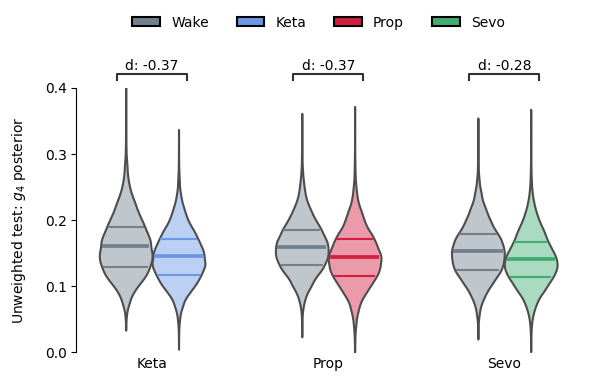

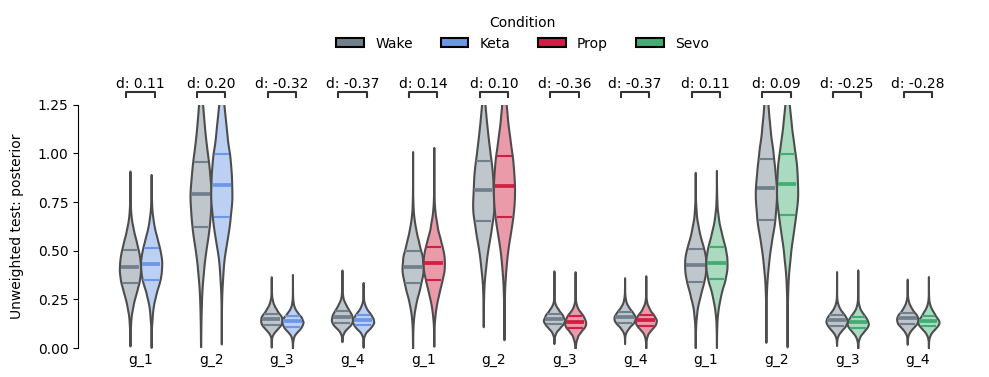

In [301]:
dataset_to_plot = 'prop'
sel_param = 'g_4'

fig1, ax1 = plt.subplots(figsize=(6, 4))
plotting.plot_single_dataset_comparison(fig1, ax1, theta_df_u, dataset_to_plot, plotting.DATASET_PALETTES[dataset_to_plot],
                                         lw=1.5, legend=True, saturation=0.9, custom_labels=list(param_labels.values()),
                                         ylabel='Unweighted test: posterior', width=0.6, labelpad=12, lgd_loc=(0.35, 1.2),
                                         y_lim=(0, 1.25), y_ticks=(0, 0.25, 0.50, 0.75, 1.0, 1.25),
                                         theta_column='theta_label')

fig2, ax2 = plt.subplots(figsize=(6, 4))
plotting.plot_parameter_across_datasets(fig2, ax2, theta_df_u, sel_param, anes_keys, plotting.DATASET_PALETTES,
                                         lw=1.5, legend=True, saturation=0.9,
                                         ylabel=f'Unweighted test: {param_labels[sel_param]} posterior',
                                         width=0.6, labelpad=12, lgd_loc=(0.1, 1.2), theta_column='theta_label',
                                         y_lim=(0, 0.4), y_ticks=(0, 0.1, 0.2, 0.3, 0.4))

fig3, ax3 = plt.subplots(figsize=(10, 4))
plotting.plot_pooled_posteriors(fig3, ax3, theta_df_u, anes_keys, plotting.DATASET_PALETTES, lw=1.5, legend=True,
                                 saturation=0.9, ylabel='Unweighted test: posterior', width=0.6, lgd_loc=(0.28, 1.2),
                                 theta_column='theta_label', y_lim=(0, 1.25), y_ticks=(0, 0.25, 0.50, 0.75, 1.0, 1.25))

plt.show()

These results look really similar to the results of P0.

## Comparing P0 posterior with unweigthed posterior

Direct comparison against Pipeline 0's weighted posterior, one parameter:

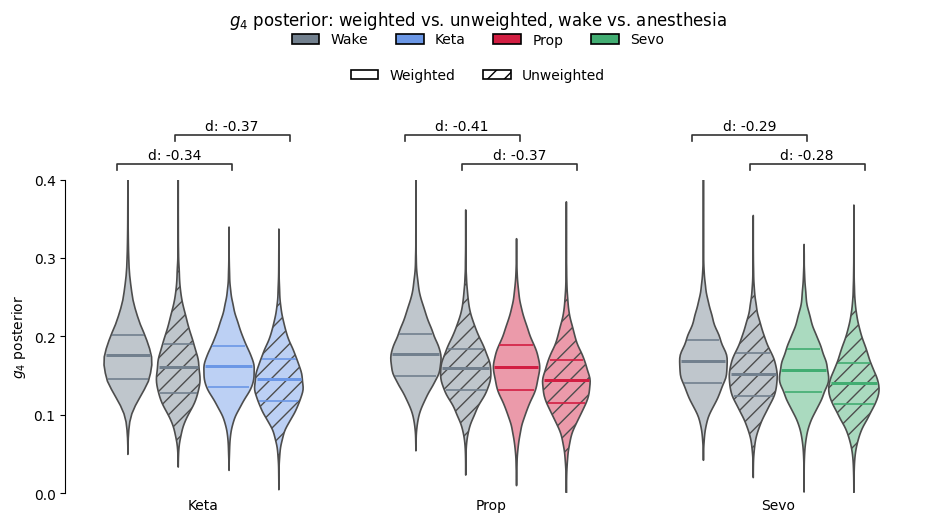

In [307]:
sel_param = 'g_4'

fig, ax = plt.subplots(figsize=(11, 5.5))
plotting.plot_weighted_vs_unweighted_comparison(
    fig, ax, theta_df_p0, theta_df_u, sel_param, anes_keys, plotting.DATASET_PALETTES,
    ylabel=f'{param_labels[sel_param]} posterior', lw=1.2, saturation=0.9, width=0.7,
    suptitle=f'{param_labels[sel_param]} posterior: weighted vs. unweighted, wake vs. anesthesia',
    y_lim=(0, 0.4), y_ticks=(0, 0.1, 0.2, 0.3, 0.4))
plt.show()

For $g_4$, weighted separates wake from anesthesia a tiny bit more than unweighted does. 

That is a bit counterintuitive, since unweighted's raw PCIst distribution covered the empirical range better (see the delay range sweep near the top of this notebook). So better empirical coverage does not automatically mean a more informative posterior, the two are just different properties of the gain matrix.

What both variants agree on is the direction: $g_4$ (and the same holds for the other parameters as well) comes out higher under wake than under anesthesia, for all three anesthetics, whether we use the weighted or the unweighted gain matrix. That direction is also what Pipeline 0, 1 and 2 all agree on above, and it gets a lot more pronounced once the gain matrix gets more condition specific (see the conclusion below for the numbers). The full picture across every pipeline, and what to actually take away from all of this, is in the conclusion at the end of the notebook.

## Comparing pipelines on one shared prior sample

Now we will compare the different 16 channel simulations from the different pipelines (and unweigthed) with the different emperical average ERP's. To see wether they look a bit alike.

We use one fixed theta sample (the same one already used for the parameter recovery checks above), for all following plots in this section.

In [303]:
emp_cond_avg = {'wake': global_wake_p1}
for anes_name in anes_keys:
    erp_data = erp_datasets[anes_name]
    anes_cond = infr.get_anes_cond_label(erp_data)
    emp_cond_avg[anes_name] = erp_data.sel(condition=anes_cond).mean(dim='subject').dropna('region').to_numpy()

print('emp_cond_avg keys:', list(emp_cond_avg.keys()))
print('theta_true_sample (shared across every plot below):', theta_true_sample.numpy())

emp_cond_avg keys: ['wake', 'keta', 'prop', 'sevo']
theta_true_sample (shared across every plot below): [0.54846036 1.0475941  0.15425341 0.14069472]


### Plot 1: grand average vs. Pipeline 0 and unweighted

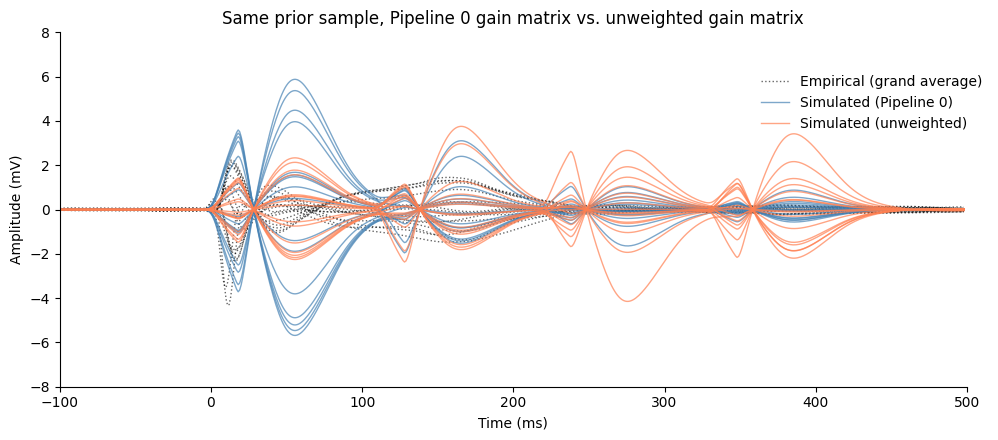

In [304]:
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(ts[::ds_sim], avg_erp, lw=1, alpha=0.6, ls=':', c='k', label='Empirical (grand average)')
ax.plot(ts[::ds_sim], sensor_true, lw=1, alpha=0.7, ls='-', c='steelblue', label='Simulated (Pipeline 0)')
ax.plot(ts[::ds_sim], sensor_true_u, lw=1, alpha=0.7, ls='-', c='coral', label='Simulated (unweighted)')

ax.set_xlabel('Time (ms)')
ax.set_ylabel('Amplitude (mV)')
ax.set_title('Same prior sample, Pipeline 0 gain matrix vs. unweighted gain matrix')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(-100, 500))
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 0.85))
fig.tight_layout()
plt.show()

In this plot we see clearly that the unweighted gain matrix simulations last longer in time than the weigthed ones. This is because in the case of weigthed, the first principal components get a bigger weigth, therefore the undelelayed simulation has the biggest amplitude, the delated copies are damped (because of lower weigth) and therefore the amplitude lowers in the 16 channel simulation  as a function of time.

### Plot 2: wake vs. anesthesia, Pipeline 1

Now we have the same simulated 1 channel waveform which we project through the wake gain matrix vs. the anesthesia gain matrix.

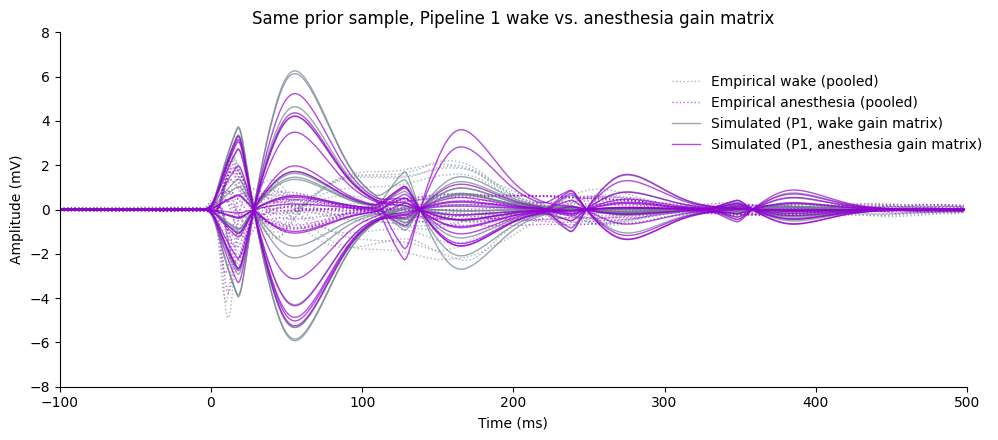

In [305]:
sensor_true_p1_wake = infr.compute_forward_solution_multimode_jax(erp_true_ds, gains_p1['wake']).T
sensor_true_p1_anes = infr.compute_forward_solution_multimode_jax(erp_true_ds, gains_p1['anes']).T

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(ts[::ds_sim], global_wake_p1, lw=1, alpha=0.6, ls=':', c=plotting.ANES_COLORS['wake'], label='Empirical wake (pooled)')
ax.plot(ts[::ds_sim], global_anes_p1, lw=1, alpha=0.6, ls=':', c='darkviolet', label='Empirical anesthesia (pooled)')
ax.plot(ts[::ds_sim], sensor_true_p1_wake, lw=1, alpha=0.7, ls='-', c=plotting.ANES_COLORS['wake'], label='Simulated (P1, wake gain matrix)')
ax.plot(ts[::ds_sim], sensor_true_p1_anes, lw=1, alpha=0.7, ls='-', c='darkviolet', label='Simulated (P1, anesthesia gain matrix)')

ax.set_xlabel('Time (ms)')
ax.set_ylabel('Amplitude (mV)')
ax.set_title('Same prior sample, Pipeline 1 wake vs. anesthesia gain matrix')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(-100, 500))
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 0.85))
fig.tight_layout()
plt.show()

### Plot 3: per condition, Pipeline 2

Now we do the same, but in the case of Pipeline 2.

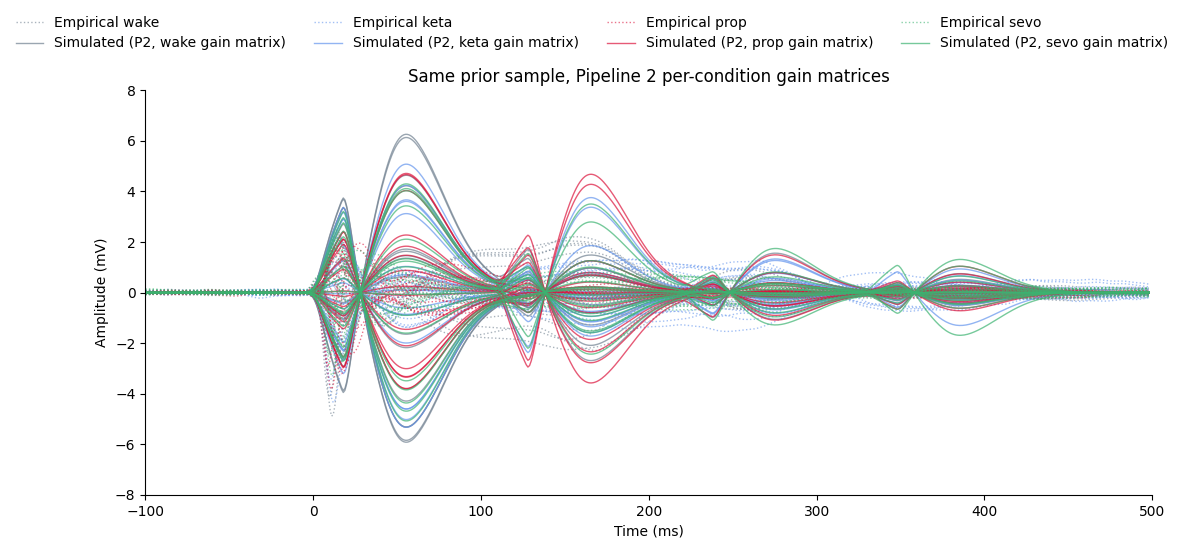

In [306]:
gain_keys_p2 = ['wake'] + anes_keys  # wake, keta, prop, sevo

sensor_true_p2 = {cond: infr.compute_forward_solution_multimode_jax(erp_true_ds, gains_p2[cond]).T for cond in gain_keys_p2}

fig, ax = plt.subplots(figsize=(11, 5))

for cond in gain_keys_p2:
    color = plotting.ANES_COLORS[cond]
    ax.plot(ts[::ds_sim], emp_cond_avg[cond], lw=1, alpha=0.6, ls=':', c=color, label=f'Empirical {cond}')
    ax.plot(ts[::ds_sim], sensor_true_p2[cond], lw=1, alpha=0.7, ls='-', c=color, label=f'Simulated (P2, {cond} gain matrix)')

ax.set_xlabel('Time (ms)')
ax.set_ylabel('Amplitude (mV)')
ax.set_title('Same prior sample, Pipeline 2 per-condition gain matrices')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(-100, 500))
plotting.dedupe_legend(fig, frameon=False, bbox_to_anchor=(1, 1.1), ncol=4)
fig.tight_layout()
plt.show()

## Wrap-up

**Worth mentioning:**

- **Gain matrix invariance, and why `weight_by_variance` matters.** With the default unit-norm gain matrices, PCIst computed through this project's
  forward projection is exactly invariant to which gain matrix is used, proven mathematically and confirmed numerically in Pipeline 1. That would
  make Pipelines 1 to 4's condition/subject/trial encoding carry zero real training signal. This notebook uses `weight_by_variance_gain = True`
  instead, which breaks that invariance and gives the encoding a real spatial handle to learn from.

  
- **Rescaling per pipeline, and why that's still fine.** Each pipeline's simulated PCIst gets its own linear rescale onto the empirical range instead of one shared pair reused everywhere, because each pipeline's gain matrix genuinely gives PCIst a different raw scale (the same reason the invariance section above cares which gain matrix is used at all, this is that same fact showing up again). The rescale only shifts and stretches where the simulated distribution sits, so SNPE trains on PCIst values that actually cover what it gets queried with later. It never touches the PCIst vs theta relationship itself, or how much real information a given gain matrix carries, that is set entirely by the simulation and the gain matrix, rescaling is a training support fix, not a reinterpretation of what PCIst means.


- **Gain matrix as convenience, not physiology.** The delayed-copy construction that turns one simulated channel into 16 sensor channels is a
  modeling trick to make PCIst computable on model output, not a claim about real propagation delays. And it's also the reason the forward projected simulations in the comparison plots above don't look like a plausible real 16 channel EEG trace (see the conclusion below).

**Known limitations worth keeping in mind:**

- Even with `weight_by_variance_gain = True`, the underlying signal is still a single simulated source, so the real information the encoding can carry
  stays limited. Simulating several coupled Jansen-Rit sources instead of one would be the more complete fix, a bigger rebuild than fit in the time
  available here.

## Conclusion

**What is the conclusion of this notebook, and do we have good results?** Mixed: single trace recovery still misses the secondary hump and recovered theta sits fairly close to the prior, not a precise fit. But the narrower question, whether PCIst carries usable information about theta that lines up with something real, holds up.

**What g parameters are bigger in which conditions?** All four, and the direction never flips anywhere in this notebook: $g_1$ and $g_2$ come out higher under anesthesia, $g_3$ and $g_4$ come out higher under wake, for all three anesthetics, under every pipeline (P0, P1, P2) and the unweighted sanity check. Magnitude-wise (Cohen's d, prop vs wake): P0 gives roughly 0.15/0.21/-0.36/-0.41 for $g_1$ to $g_4$; P1 roughly doubles all four to 0.38/0.54/-0.85/-0.96; P2 then diverges, $g_2$ and $g_4$ keep growing (0.91, -1.45) while $g_1$ and $g_3$ shrink back down (0.11, -0.42).

**Can we even trust this?** Yes: the direction holds for all four parameters, across every pipeline and gain matrix variant tried, and gets stronger as the gain matrix gets more condition specific, exactly the pattern we would want from a real signal rather than noise. The exact d-values still depend on modeling choices with no single correct setting (variance weighting, `dmax`), but we can trust the direction, we just have to treat the specific numbers as tied to this particular setup.

**Is unweighted or weighted the way to go, and why do they give different results?** Weighted is still the practical choice, since it's the only variant that breaks PCIst invariance and lets Pipelines 1 to 4 condition on anything at all, and it clearly pulls ahead once the gain matrix gets condition specific (P2 reaches d up to 0.91/-1.45 versus unweighted's 0.10/-0.37). But at the single-gain-matrix level (P0 vs. the unweighted test, both at their own best dmax), the two are now close to a wash for $g_4$: weighted edges ahead for prop and sevo, unweighted edges ahead for keta, all differences small (within about 0.04 of each other). So "weighted separates more" is really a P1/P2 story, not a property of the raw gain matrix choice itself. Unweighted's other advantage, empirical PCIst coverage, still holds.

**Would the result depend on `dmax`? Why is this (un)acceptable?** Yes, and this notebook now shows it: weighted and unweighted are deliberately run at different `dmax` values (330 vs. 420) because each variant's own spread/sensitivity peaks in a different place. That's a real weakness for recovering one dmax-independent value, but acceptable given the actual goal, since the direction of the effect stays the same regardless.

**Do the simulations look realistic with this `dmax`, and why does this not really matter?** No, the 16 channel projection is dominated by repeated echoes rather than a decaying evoked response, expected from the delayed-copy trick. Doesn't matter here since the notebook only needs simulated PCIst to span the empirical range and to carry a real theta relationship, not to look like plausible raw EEG.

## Final conclusion: comparing Notebook 2 and Notebook 3

**Do the two notebooks agree?** Yes, on the two parameters where each notebook actually found a real signal. $g_2$ (and $g_1$) come out higher under anesthesia than wake in both notebooks, for keta, prop and sevo separately, and $g_4$ (and $g_3$) comes out higher under wake than under any anesthetic, again in both. That is meaningful, because the two notebooks got there in completely different ways: Notebook 2 fits the raw averaged waveform directly with NUTS, Notebook 3 never even looks at the waveform, it only sees a single PCIst number per recording and learns from thousands of simulations with SBI. Two very different pipelines landing on the same direction is a really strong sign. The results on $g_1$ and $g_3$ are weaker then the results on $g_2$ and $g_4$ in both notebooks, but the results from the 2 notebooks on these parameters still agree.

**Are we sure this is true?** Sure enough to say it is probably a real effect, not sure enough to call it settled. The direction agrees across two independent methods, which is reassuring. But both notebooks share the same underlying simplifications: only 4 of the 10 Jansen-Rit parameters are ever allowed to vary, the data gets pooled into grand averages that hide subject-to-subject and trial-to-trial variability (Notebook 2's posteriors were suspiciously narrow because of exactly this), and Notebook 3 depends on a somewhat artificial gain matrix/delay trick to turn one source into 16 channels. Any of those choices could be quietly shaping the result. So to conclude, we should trust the direction, but be careful with the exact numbers, and we should not treat this as a certain proof.

**Can we explain it physically?** Looking at how $g_1$ to $g_4$ actually enter the Jansen-Rit equations: $g_2$ is the gain of the feedback loop from the excitatory interneurons back to the pyramidal cells, and $g_4$ is the gain of the feedback loop from the inhibitory interneurons back to the pyramidal cells. So what we are seeing is the excitatory feedback getting stronger and the inhibitory feedback getting weaker under anesthesia, relative to wake. That is a bit surprising at first glance, propofol and sevoflurane are "GABA" boosters, so the naive guess would be more inhibition under anesthesia, not less.

**Did the method work, or did it fail?** It worked as intended: a rough model was used, and it still turned up a real, reproducible signal that two independent methods agree on. But there is a difference between "detects a real difference" and "gives an accurate model of the brain". The posterior predictive checks in Notebook 2 show the g-only model missing part of the waveform shape for several conditions, and Notebook 3's own parameter recovery test was not precise either. This is a working proof of concept that finds something real, but these two methods are not finished yet.

**What else to do?** If I had more time I would do the following things: I would refine it first, before moving to human EEG. For example:
- Trying the fit with more than just the 4 gain parameters free (Notebook 2 already showed this gives a clearly better waveform fit)
- Trying to find a better brain Model than Jansen Rit
- Trying to find a better way to simulate 16 channel data
- Try it on Human EEG data

Runtime untill here (if simulations andd PCIst not performed again): 475 sec

## Appendix: Pipelines 3 and 4 (optional, slow, not updated code!)

FROM HERE ON OUT THE REST OF THE NOTEBOOK IS NOT WORKING ANYMORE!!


Pipelines 3 (per subject, per condition gain matrices) and 4 (per subject,
per condition, per trial) are kept here for completeness, but they are not
part of the main flow anymore. Both retrain the whole SBI dataset with many
more gain matrices than P0 to P2 (P4 additionally loops over every subject
and trial), so they are slow, especially on a 4GB laptop GPU, and rerunning
them every time this notebook runs is not worth it for what they show: the
posteriors they produce do not look meaningfully better than P0 to P2's, see
the comparison plots earlier in this notebook for that baseline.

The code below is unchanged from when these were part of the main pipeline
progression, it is just moved down here so the notebook stays fast to rerun
top to bottom. Skip this section unless specifically checking P3/P4 again.

## Pipeline 3: personalized gains (per subject, per condition)

Now a gain matrix per subject per condition, still on the trial-averaged
data. Encoding grows to the 4-way condition one-hot plus a one-hot over every
subject in the combined dataset (`n_global_subjects` columns). `gains_p3` is
nested `gains_p3[anes_name][subject][condition]`, `make_sbi_dataset` derives
the global, sorted subject list straight from this dict, and we reuse that
exact same list below (`global_subjects_p3`) when building the empirical
features, so the one-hot column positions line up with what the network was
actually trained on.

**Wake pooling:** wake is recorded once per anesthesia session (see
`data.py`), so a subject who took part in all three anesthesia sessions has
three separate wake recordings, one alongside each anesthetic. `wake` is the
same underlying condition every time though, so `compute_shared_gain`
defaults to `pool_wake_across_sessions=True`: it averages a subject's wake
ERP across every session they appear in first, and uses that single pooled
wake gain matrix everywhere for that subject, instead of a different wake
gain matrix per session. This is the same idea Pipeline 2 already applies
when it pools wake across subjects, just one level down. Pass
`pool_wake_across_sessions=False` to get the old per-session behaviour back
(keeps the wake and anesthesia recording montage matched within a session,
at the cost of treating wake as three different conditions).


In [ ]:
pipeline = 3

gains_p3 = infr.compute_shared_gain(erp_datasets, anes_keys=anes_keys, pipeline=pipeline, num_components=num_components,
                                     weight_by_variance=weight_by_variance_gain)
global_subjects_p3 = sorted({subj for subj_dict in gains_p3.values() for subj in subj_dict.keys()})
print(f'{len(global_subjects_p3)} subjects total:', global_subjects_p3)

In [ ]:
theta_arr_p3, feature_array_p3 = infr.make_sbi_dataset(
    sim_array.to_numpy(), theta, gains_p3, time_vec, pci_pars, pipeline,
    forward_chunks=forward_chunks, pci_chunks=pci_chunks)

# same rescale as Pipeline 0, see "Rescaling simulated PCIst" above
feature_array_p3[:, 0] = infr.apply_pcist_rescale(feature_array_p3[:, 0], a_weighted, b_weighted)
print(theta_arr_p3.shape, feature_array_p3.shape)  # expect (num_sim * n_subjects * 2, num_params), (…, 1 + 4 + n_subjects)

In [ ]:
x_features_p3 = feature_array_p3.numpy()
if normalize_features:
    scaler_p3 = preprocessing.MinMaxScaler()
    x_features_p3[:, 0:1] = scaler_p3.fit_transform(x_features_p3[:, 0:1])
x_features_p3 = torch.as_tensor(x_features_p3.astype(np.float32))
theta_tensor_p3 = torch.as_tensor(theta_arr_p3, dtype=torch.float32)

In [ ]:
pci_values_p3 = x_features_p3[:, 0]
fig, axes = plotting.plot_pci_vs_params(theta_arr_p3, pci_values_p3, prm_names, param_labels,
                                         title='PCIst vs. parameters (Pipeline 3)')
plt.show()

This is the more expensive training cell so far, `x_features_p3` has
`num_sim * n_subjects * 2` rows instead of `num_sim` or `num_sim * a handful`.

In [ ]:
inference_nn_p3 = sbi.inference.SNPE(prior, density_estimator=estimator_type, device=device)
posterior_estimator_p3 = inference_nn_p3.append_simulations(theta_tensor_p3, x_features_p3).train()
posterior_p3 = sbi.inference.DirectPosterior(posterior_estimator_p3, prior)

Posterior sampling: `build_empirical_features(..., subject_index=global_subjects_p3)`
takes care of the per-subject one-hot encoding, and `sample_batched` can take
the whole (subject, condition) table for one anesthesia dataset at once,
there is no need to loop subject by subject here even though each row has a
different one-hot column, `sample_batched` samples every row independently.

In [ ]:
all_posteriors_p3 = {}

for anes_name in anes_keys:
    emp_features = emp_feature_dict[anes_name]
    emp_array = infr.build_empirical_features(emp_features, pipeline, subject_index=global_subjects_p3)
    if normalize_features:
        # scaler_p3, not global_emp_max, see the note on this fix in Pipeline 0 above
        emp_array[:, 0:1] = scaler_p3.transform(emp_array[:, 0:1])

    emp_tensor = torch.tensor(emp_array, dtype=torch.float32)
    theta_samples = posterior_p3.sample_batched(sample_shape=(num_samples,), x=emp_tensor, show_progress_bars=False)

    n_subjects = emp_features.sizes['subject']
    n_conditions = emp_features.sizes['condition']
    # build_empirical_features iterates condition first, then subject, matching this reshape order,
    # see the comment under Pipeline 1 for why the permute right after the reshape matters
    theta_samples = theta_samples.permute(1, 0, 2).reshape(n_conditions, n_subjects, num_samples, num_params).permute(1, 0, 3, 2)

    all_posteriors_p3[anes_name] = xr.DataArray(
        theta_samples.numpy(), dims=posterior_dims,
        coords=dict(subject=emp_features.subject, condition=emp_features.condition, theta=prm_names))

    print(f'{anes_name}: posterior shape {all_posteriors_p3[anes_name].shape}')

**A note on `torch.load`, `weights_only` and other reproducibility details:
if the row order or reshape target here ever looks scrambled (a subject's
posterior visibly matching a different subject's empirical PCIst), the first
thing to check is whether `build_empirical_features`'s condition/subject loop
order still matches the `.reshape(...)` above, that ordering is the one thing
in this cell that isn't checked automatically, everything else (the encoding
width, the subject list) is derived directly from `gains_p3`.**

In [ ]:
if normalize_posteriors:
    stacked_p3 = xr.concat(list(all_posteriors_p3.values()), dim='anes')
    global_param_max_p3 = stacked_p3.max(('anes', 'subject', 'condition', 'sample'))
    for anes_name in anes_keys:
        all_posteriors_p3[anes_name] = all_posteriors_p3[anes_name] / global_param_max_p3

for anes_name in anes_keys:
    out_dir = f'output/{pipeline}_{num_sim}/{anes_name}'
    os.makedirs(out_dir, exist_ok=True)
    all_posteriors_p3[anes_name].to_netcdf(out_dir + f'/theta_posteriors_{pipeline}_{anes_name}.nc')

theta_df_p3 = infr.pool_posteriors(all_posteriors_p3)

In [ ]:
dataset_to_plot = 'keta'
sel_param = 'g_4'

fig1, ax1 = plt.subplots(figsize=(8, 5))
plotting.plot_single_dataset_comparison(fig1, ax1, theta_df_p3, dataset_to_plot, plotting.DATASET_PALETTES[dataset_to_plot],
                                         lw=1.5, legend=True, saturation=0.9, custom_labels=list(param_labels.values()),
                                         ylabel='Pipeline 3: posterior (normalized)', width=0.6, labelpad=12,
                                         lgd_loc=(0.35, 1.2), theta_column='theta_label')

fig2, ax2 = plt.subplots(figsize=(8, 5))
plotting.plot_parameter_across_datasets(fig2, ax2, theta_df_p3, sel_param, anes_keys, plotting.DATASET_PALETTES,
                                         lw=1.5, legend=False, saturation=0.9,
                                         ylabel=f'Pipeline 3: {param_labels[sel_param]} posterior (normalized)',
                                         width=0.6, labelpad=12, lgd_loc=(0.2, 1.2), theta_column='theta_label')
plt.show()

## Pipeline 4: personalized gains, per subject, per condition, per trial

Same idea as Pipeline 3, but on individual trials instead of the trial
average, gain matrices become `gains_p4[anes_name][subject][trial][condition]`,
and the encoding grows again with a one-hot over trials.

**Per-trial gain matrix, wake vs anesthesia**

`gains_p4` gets used two places, different amount of wake detail needed:

- *Training set (`make_sbi_dataset`)*: with `weight_by_variance_gain = True`,
  simulated PCIst does depend a bit on which gain matrix was used (see the
  invariance section under Pipeline 1), so pooling a subject's wake sessions
  into one gain matrix is no longer a completely free simplification, three
  separate session gain matrices could in principle give slightly different
  simulated PCIst-vs-theta curves. Kept anyway for consistency with Pipeline
  3 and to keep the cost down, worth listing as a real, probably small,
  limitation rather than a non-issue.
- *Empirical query (`build_empirical_features`, `pci_trial_datasets_p4`)*:
  real per-trial detail lives here regardless, untouched by pooling.
  `n_trials_p4` genuinely different real wake PCIst values per session.

The wake/anesthesia asymmetry (a subject with 3 sessions has up to 3x more
wake trials than any single anesthesia condition) is real, but most of that
richness is already in the empirical data on the query side.

Wake trial 0 and keta trial 0 aren't paired (independent recordings, index
just coincides), so trial-resolved wake gain matrices don't mean anything
anyway. `pool_wake_across_sessions=True` (default): one wake gain matrix per
subject, averaged over trials and sessions, reused for every anesthesia
trial. `=False`: back to one per subject/trial/session, own session's wake
only.

**Cost**: `n_subjects * n_trials * 2` gain matrices vs Pipeline 3's
`n_subjects * 2`. Using `n_trials_p4 = 2` (of 5 saved), same reasoning as
the original notebook ("otherwise too expensive"). Bump to
`trial_datasets['keta'].sizes['trial']` (5) if GPU headroom allows.

In [ ]:
pipeline = 4

n_trials_p4 = 2  # out of the 5 trials Notebook 1 saved, see the cost note above
trial_datasets_p4 = {a: trial_datasets[a].isel(trial=slice(0, n_trials_p4)) for a in anes_keys}
pci_trial_datasets_p4 = {a: pci_trial_datasets[a].isel(trial=slice(0, n_trials_p4)) for a in anes_keys}

gains_p4 = infr.compute_shared_gain(trial_datasets_p4, anes_keys=anes_keys, pipeline=pipeline, num_components=num_components,
                                     weight_by_variance=weight_by_variance_gain)

global_subjects_p4 = sorted({subj for subj_dict in gains_p4.values() for subj in subj_dict.keys()})
global_trials_p4 = sorted({tr for subj_dict in gains_p4.values() for trial_dict in subj_dict.values() for tr in trial_dict.keys()})
print(f'{len(global_subjects_p4)} subjects, {len(global_trials_p4)} trials used')

In [ ]:
theta_arr_p4, feature_array_p4 = infr.make_sbi_dataset(
    sim_array.to_numpy(), theta, gains_p4, time_vec, pci_pars, pipeline,
    forward_chunks=forward_chunks, pci_chunks=pci_chunks)

# same rescale as Pipeline 0, see "Rescaling simulated PCIst" above
feature_array_p4[:, 0] = infr.apply_pcist_rescale(feature_array_p4[:, 0], a_weighted, b_weighted)
print(theta_arr_p4.shape, feature_array_p4.shape)
# expect (num_sim * n_subjects * n_trials * 2, num_params), (…, 1 + 4 + n_subjects + n_trials)

In [ ]:
x_features_p4 = feature_array_p4.numpy()
if normalize_features:
    scaler_p4 = preprocessing.MinMaxScaler()
    x_features_p4[:, 0:1] = scaler_p4.fit_transform(x_features_p4[:, 0:1])
x_features_p4 = torch.as_tensor(x_features_p4.astype(np.float32))
theta_tensor_p4 = torch.as_tensor(theta_arr_p4, dtype=torch.float32)

In [ ]:
pci_values_p4 = x_features_p4[:, 0]
fig, axes = plotting.plot_pci_vs_params(theta_arr_p4, pci_values_p4, prm_names, param_labels,
                                         title='PCIst vs. parameters (Pipeline 4)')
plt.show()

In [ ]:
inference_nn_p4 = sbi.inference.SNPE(prior, density_estimator=estimator_type, device=device)
posterior_estimator_p4 = inference_nn_p4.append_simulations(theta_tensor_p4, x_features_p4).train()
posterior_p4 = sbi.inference.DirectPosterior(posterior_estimator_p4, prior)

Posterior sampling: empirical PCIst here comes from `pci_trial_datasets_p4`
(the trial-resolved values saved by Notebook 1), not from `emp_feature_dict`
(the trial-averaged ones used by pipelines 0 to 3). Mixing those two up is
an easy mistake to make since they have almost the same name, it's what
caused this section to fail outright in the original version of this
notebook (the trial-averaged empirical dict has no `trial` dimension to loop
over, and it never even used the trial-resolved values it had loaded a few
cells earlier).

Since `build_empirical_features` loops condition slowest, subject in the
middle, trial fastest for pipeline 4, the reshape below mirrors that: reshape
the raw batch into `(n_conditions, n_subjects, n_trials, ...)` first, then
transpose into the `(subject, condition, trial, ...)` order the xarray
coordinates use.

In [ ]:
all_posteriors_p4 = {}

for anes_name in anes_keys:
    emp_features = pci_trial_datasets_p4[anes_name]
    emp_array = infr.build_empirical_features(emp_features, pipeline, subject_index=global_subjects_p4, trial_index=global_trials_p4)
    if normalize_features:
        # scaler_p4, not global_emp_max, see the note on this fix in Pipeline 0 above
        emp_array[:, 0:1] = scaler_p4.transform(emp_array[:, 0:1])

    emp_tensor = torch.tensor(emp_array, dtype=torch.float32)
    theta_samples = posterior_p4.sample_batched(sample_shape=(num_samples,), x=emp_tensor, show_progress_bars=False)

    n_subjects = emp_features.sizes['subject']
    n_conditions = emp_features.sizes['condition']
    n_trials = emp_features.sizes['trial']

    theta_samples = theta_samples.permute(1, 0, 2)  # (B, num_samples, theta)
    theta_samples = theta_samples.reshape(n_conditions, n_subjects, n_trials, num_samples, num_params)
    theta_samples = theta_samples.permute(1, 0, 2, 4, 3)  # -> (subject, condition, trial, theta, sample)

    all_posteriors_p4[anes_name] = xr.DataArray(
        theta_samples.numpy(), dims=('subject', 'condition', 'trial', 'theta', 'sample'),
        coords=dict(subject=emp_features.subject, condition=emp_features.condition, trial=emp_features.trial, theta=prm_names))

    print(f'{anes_name}: posterior shape {all_posteriors_p4[anes_name].shape}')

In [ ]:
if normalize_posteriors:
    stacked_p4 = xr.concat(list(all_posteriors_p4.values()), dim='anes')
    global_param_max_p4 = stacked_p4.max(('anes', 'subject', 'condition', 'trial', 'sample'))
    for anes_name in anes_keys:
        all_posteriors_p4[anes_name] = all_posteriors_p4[anes_name] / global_param_max_p4

for anes_name in anes_keys:
    out_dir = f'output/{pipeline}_{num_sim}/{anes_name}'
    os.makedirs(out_dir, exist_ok=True)
    all_posteriors_p4[anes_name].to_netcdf(out_dir + f'/theta_posteriors_{pipeline}_{anes_name}.nc')

# average over trial here so pool_posteriors gets the same (subject, condition, theta, sample)
# shape the plotting helpers expect, the per-trial posteriors are still on disk if needed later
theta_df_p4 = infr.pool_posteriors({a: all_posteriors_p4[a].mean('trial') for a in anes_keys})

### Plotting Pipeline 4

Keep in mind this is the average of the per-trial posteriors, not a single
posterior computed from trial-averaged data (that's Pipeline 3).

In [ ]:
dataset_to_plot = 'keta'
sel_param = 'g_4'

fig1, ax1 = plt.subplots(figsize=(8, 5))
plotting.plot_single_dataset_comparison(fig1, ax1, theta_df_p4, dataset_to_plot, plotting.DATASET_PALETTES[dataset_to_plot],
                                         lw=1.5, legend=True, saturation=0.9, custom_labels=list(param_labels.values()),
                                         ylabel='Pipeline 4: posterior (normalized)', width=0.6, labelpad=12,
                                         lgd_loc=(0.35, 1.2), theta_column='theta_label')

fig2, ax2 = plt.subplots(figsize=(8, 5))
plotting.plot_parameter_across_datasets(fig2, ax2, theta_df_p4, sel_param, anes_keys, plotting.DATASET_PALETTES,
                                         lw=1.5, legend=False, saturation=0.9,
                                         ylabel=f'Pipeline 4: {param_labels[sel_param]} posterior (normalized)',
                                         width=0.6, labelpad=12, lgd_loc=(0.2, 1.2), theta_column='theta_label')

fig3, ax3 = plt.subplots(figsize=(12, 6))
plotting.plot_pooled_posteriors(fig3, ax3, theta_df_p4, anes_keys, plotting.DATASET_PALETTES, lw=1.5, legend=True,
                                 saturation=0.9, ylabel='Pipeline 4: posterior (normalized)', width=0.6,
                                 theta_column='theta_label')
plt.show()